<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">03 · Computer Vision basics: Fashion-MNIST</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">An image is a grid of numbers: how does a model read it?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/02_computer_vision/01_mini_project_fashion_mnist/03_Computer_Vision_Basics_Fashion_MNIST.ipynb) [![Slides](https://img.shields.io/badge/slides-Computer_vision-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#computer-vision)

## 🎯 Objectives
This notebook follows the Computer vision slides **in the same order** and turns every idea into a picture made from real data. By the end you will be able to:

- explain why, for a computer, **an image is just a grid of numbers** (one grid per colour channel);
- **flatten** an image into 784 numbers, train the **MLP** from Lesson 02 on it, and *see* what its first layer learned;
- show, with two experiments, why flattening is a problem: a **3-pixel shift** and **shuffled pixels**;
- apply a **kernel** by hand, slide it over an image step by step, and explain **feature maps** and **pooling**;
- train a small **CNN** in PyTorch, look inside it (learned kernels, feature maps layer by layer) and show it beats the MLP with **far fewer parameters**;
- read a 10-class **confusion matrix**, find the most confused pairs, and ask the model **where it looked** (saliency maps).

**📋 Prerequisites:** Lesson 02 (MLP, PyTorch training loop, confusion matrix, overfitting) and the Computer vision slides · **▶️ How to use:** run the cells in order with `Shift`+`Enter`; try the ✏️ exercises before opening the solutions. The whole notebook runs in about 2 minutes on a laptop CPU.

<sub>Some analyses (saliency maps per class, the "clothes vs shoes & bags" view of the confusion matrix, the learning-rate comparison) are inspired by a Computer Vision project by Diogo Freitas, João Francisco Botas, Miguel Gonçalves and Ricardo Galvão.</sub>

## 📑 Contents

1. [👁️ What is computer vision?](#sec-1)
2. [🔢 An image is a grid of numbers](#sec-2)
3. [👗 The task and the dataset: Fashion-MNIST](#sec-3)
4. [📏 One item = 784 numbers](#sec-4)
5. [🧮 First idea: flatten and feed the MLP](#sec-5)
6. [🧩 The problem: flattening forgets the neighbours](#sec-6)
7. [💡 A better idea: look at small patches](#sec-7)
8. [✖️ A kernel: multiply, then add](#sec-8)
9. [🎞️ Slide the kernel: a feature map](#sec-9)
10. [🗂️ Many kernels, many feature maps](#sec-10)
11. [🔽 Pooling: shrink, keep the strongest](#sec-11)
12. [🧱 Stack layers](#sec-12)
13. [⚖️ MLP vs CNN: what changes](#sec-13)
14. [🧑‍💻 The code: train a small CNN and look inside](#sec-14)
15. [🏆 The evidence: ImageNet, and our own final exam](#sec-15)
16. [🔬 Where does the model look, and what did it learn?](#sec-16)
17. [✏️ Exercises](#sec-17)
18. [📌 Summary](#sec-18)
19. [📚 Learn more](#sec-19)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    os.chdir(ROOT)  # Colab already has torch, torchvision, matplotlib and ipywidgets: nothing to install
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time
from io import BytesIO

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Image as IPyImage, display
from matplotlib.patches import Rectangle
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from src.paths import cache_dir, models_dir
from src.plotting import PALETTE, apply_style, label_bars, plot_confusion, plot_history
from src.vision import (FASHION_CLASSES, KERNELS, apply_kernel, capture_activations, count_parameters,
                        evaluate, input_gradients, load_fashion_mnist, load_image, number_grid,
                        resize_center_crop, save_slide_image, set_seed, shift_images, show_grid, train_model)

apply_style()
mpl.rcParams["figure.dpi"] = 85             # sharp on screen while keeping 35+ figures compact
mpl.rcParams["savefig.dpi"] = 100
SEED = 42
set_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
T_START = time.perf_counter()

# False (default): 4 epochs per model and a t-SNE map of 2,000 images, about 2 minutes on a laptop CPU.
# True: 10 epochs for the CNN and 5,000 images in the t-SNE map (a few more minutes; numbers change a little).
RUN_HEAVY = False

PETS = ROOT / "data" / "pets" / "cropped"   # our own test pets (in the repository): used for colour photos
YELLOW = "#ffd43b"                          # the highlight colour of the slides

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        save_slide_image(fig, ROOT / "assets" / "slides" / name)

def no_axes(axes):
    for ax in np.ravel(axes):
        ax.axis("off")

def show_jpeg(fig, quality=82):
    """Show a figure full of photos as JPEG instead of PNG: it looks the same and keeps the notebook small."""
    buf = BytesIO()
    fig.savefig(buf, format="jpeg", dpi=fig.dpi, bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(IPyImage(buf.getvalue()))

print("PyTorch", torch.__version__, "| device: CPU (this notebook does not need a GPU)")

PyTorch 2.15.0+cpu | device: CPU (this notebook does not need a GPU)


> 💡 **Tip:** in Colab there is nothing to install. Locally, run `uv sync` at the project root and pick the `.venv` kernel. The first run downloads Fashion-MNIST (≈ 30 MB) into `data/_cache/`. The cells with sliders (🎛️) need `ipywidgets` (installed locally and in Colab); every idea is also shown as a normal picture, so you lose nothing if the sliders do not appear.

### 📖 Words you will meet (mini-glossary)

| Term | In plain words |
|---|---|
| **pixel** | one dot of the image; here a number from 0 (black) to 255 (white) |
| **grayscale / RGB** | one number per pixel (grey) or three numbers per pixel (red, green, blue): the **channels** |
| **resolution** | how many pixels: Fashion-MNIST images are 28 × 28 = 784 pixels |
| **flatten** | put the rows of the image one after the other, making one long list of numbers |
| **kernel (filter)** | a tiny grid of weights (e.g. 3 × 3) that slides over the image looking for one pattern |
| **convolution** | sliding the kernel over the image and, at each position, multiplying and summing |
| **feature map** | the new "image" produced by one kernel: bright where the pattern was found |
| **pooling** | shrinking a feature map by keeping the largest value of each 2 × 2 block |
| **CNN** | *convolutional neural network*: layers of kernels that are **learned**, not hand-made |
| **logits / softmax** | the raw scores of the 10 classes / the same scores turned into probabilities that add up to 1 |
| **saliency map** | a picture of which pixels would change the model's score the most |

<a id="sec-1"></a>
# 1. 👁️ What is computer vision?

> 🎞️ **Slides:** [Teaching computers to understand images](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-what) · [You use computer vision every day](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-apps)

**Computer vision** = getting useful information out of pictures and video. Three classic questions, each asking for more detail than the last:

| Task | Question | Answer |
|---|---|---|
| **classification** | *what* is in the image? | one label for the whole picture |
| **object detection** | *what* and *where*? | a box + a label for every object |
| **segmentation** | *which pixels* belong to what? | a label for every pixel |

Face unlock and photo search are classification; driver assistance and factory cameras are detection; outlining a tumour on a scan is segmentation. Today we do **classification** (detection comes back with YOLO in Challenge 2). All of them start the same way: the computer receives a photo. Let's load the photos we will use all along and draw the three tasks on them.

In [3]:
X_train_u8, y_train = load_fashion_mnist(cache_dir(), train=True)    # uint8 images, int64 labels
X_test_u8, y_test = load_fashion_mnist(cache_dir(), train=False)     # locked until section 15
first = {c: int(np.flatnonzero(y_train.numpy() == c)[0]) for c in range(10)}   # first training image of each class
print("train:", tuple(X_train_u8.shape), X_train_u8.dtype, "| test:", tuple(X_test_u8.shape))

train: (60000, 28, 28) torch.uint8 | test: (10000, 28, 28)


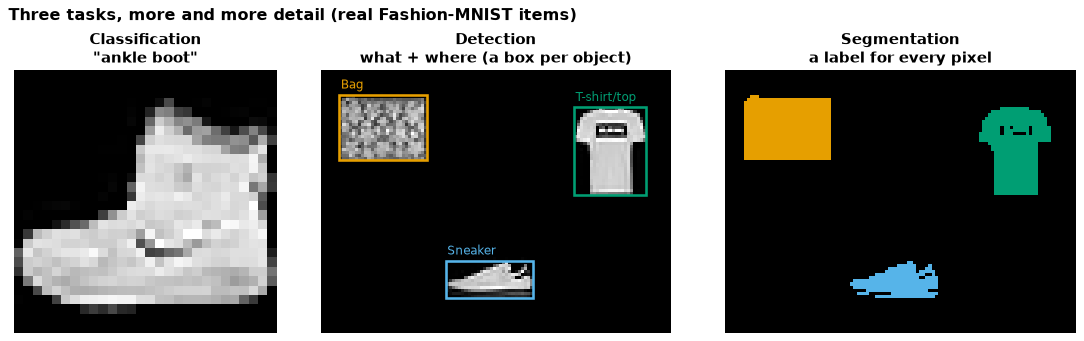

In [4]:
# A "scene" made of three real Fashion-MNIST items pasted on a black canvas
canvas = np.zeros((84, 112), dtype=np.uint8)
scene = [(8, 4, 6), (7, 52, 40), (0, 12, 78)]          # (class, top, left): a bag, a sneaker, a T-shirt
colours = [PALETTE["orange"], PALETTE["sky"], PALETTE["green"]]
segmentation = np.zeros((*canvas.shape, 3))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), width_ratios=[0.8, 1.1, 1.1], layout="constrained")
for (cls, top, left), colour in zip(scene, colours):
    item = X_train_u8[first[cls]].numpy()
    canvas[top:top + 28, left:left + 28] = item
    rows, cols = np.nonzero(item > 20)                  # the pixels that belong to the item
    axes[1].add_patch(Rectangle((left + cols.min() - .5, top + rows.min() - .5), np.ptp(cols) + 1, np.ptp(rows) + 1,
                                fill=False, ec=colour, lw=2.2))
    axes[1].text(left + cols.min(), top + rows.min() - 1.5, FASHION_CLASSES[cls], color=colour, fontsize=10, va="bottom")
    segmentation[top:top + 28, left:left + 28][item > 20] = mpl.colors.to_rgb(colour)
axes[0].imshow(X_train_u8[first[9]], cmap="gray"); axes[0].set_title('Classification\n"ankle boot"', loc="center")
axes[1].imshow(canvas, cmap="gray"); axes[1].set_title("Detection\nwhat + where (a box per object)", loc="center")
axes[2].imshow(segmentation); axes[2].set_title("Segmentation\na label for every pixel", loc="center")
no_axes(axes)
fig.suptitle("Three tasks, more and more detail (real Fashion-MNIST items)", x=0.01, ha="left", fontweight="bold")
plt.show()

<a id="sec-2"></a>
# 2. 🔢 An image is a grid of numbers

> 🎞️ **Slides:** [An image is a grid of numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-grid) · [A colour image is three grids](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-rgb) · [Zoom in until the photo becomes numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-pixels)

## 🧠 How it works: an image is a table

**Simple idea.** You see an ankle boot. The computer sees a **table of 28 rows × 28 columns**, and in each cell a number: 0 = black, 255 = white. Each cell is a **pixel** ("picture element"). There is no "boot" in the file, only 784 numbers. Remember `load_digits` in Lesson 02? Same idea, 8 × 8 cells with values 0–16.

**Steps:** (1) the camera measures the light in each tiny square; (2) each measurement becomes a number; (3) a colour photo stores **three** tables (red, green, blue); (4) the model must find "boot-ness" in those numbers.

**Analogy.** A mosaic seen from very close: each tile is just one colour. Step back and you see a picture.

**Limits.** The same boot moved 3 pixels to the right gives a *completely different list of numbers*, even though for us it is the same boot. Keep this in mind: it is the reason convolutions were invented.

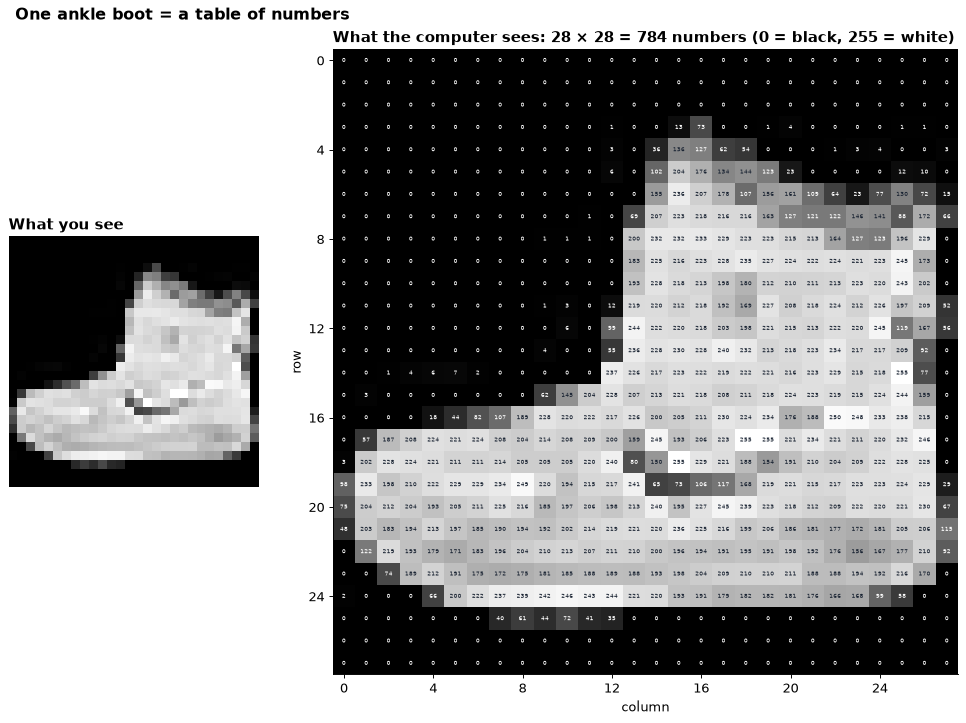

the same image as an array: (28, 28) uint8 | first non-black row: 3


In [5]:
i = first[9]                                            # the first ankle boot of the training set
img = X_train_u8[i].numpy()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 8.4), width_ratios=[1, 3], layout="constrained")
ax0.imshow(img, cmap="gray"); ax0.set_title("What you see"); ax0.axis("off")
number_grid(ax1, img, vmin=0, vmax=255, fontsize=5.2)
ax1.set_xticks(range(0, 28, 4)); ax1.set_yticks(range(0, 28, 4))
ax1.set(xlabel="column", ylabel="row", title="What the computer sees: 28 × 28 = 784 numbers (0 = black, 255 = white)")
fig.suptitle(f"One {FASHION_CLASSES[y_train[i]].lower()} = a table of numbers", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-pixel-numbers.png")
plt.show()
print("the same image as an array:", img.shape, img.dtype, "| first non-black row:", int(np.argmax(img.max(1) > 0)))

### 🎨 Colour: three grids stacked

A colour photo has **three numbers per pixel**: how much **red**, **green** and **blue** light (0–255 each). All three at 255 = white, all at 0 = black, red + green = yellow (light mixes differently from paint). Fashion-MNIST is grey, so let's borrow a colour photo: one of the test pets of notebook 04.

NumPy shape: (256, 256, 3) uint8 | PyTorch puts the channels first: (3, 256, 256)


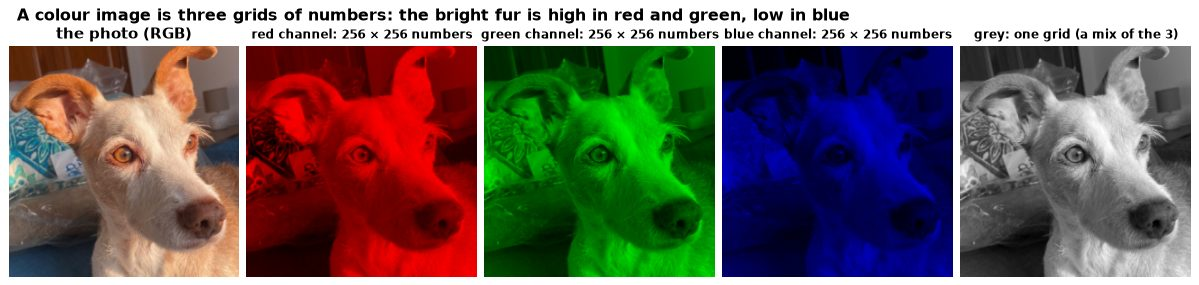

one pixel of the fur at (row 205, col 168) = (R, G, B) = (102, 83, 76)


In [6]:
dog = resize_center_crop(load_image(PETS / "dogs" / "dog9011.jpg"), 256)   # a phone photo, cut to 256 × 256
dog_np = np.array(dog)                                                      # NumPy / PIL order: (height, width, 3)
print("NumPy shape:", dog_np.shape, dog_np.dtype, "| PyTorch puts the channels first:",
      tuple(torch.from_numpy(dog_np).permute(2, 0, 1).shape))

fig, axes = plt.subplots(1, 5, figsize=(14, 3.3), layout="constrained")
axes[0].imshow(dog_np); axes[0].set_title("the photo (RGB)", loc="center")
for k, name in enumerate(("red", "green", "blue")):
    only = np.zeros_like(dog_np); only[..., k] = dog_np[..., k]           # keep one channel, the others at 0
    axes[k + 1].imshow(only); axes[k + 1].set_title(f"{name} channel: 256 × 256 numbers", loc="center", fontsize=10)
grey = np.asarray(dog.convert("L"))                                         # 0.299 R + 0.587 G + 0.114 B
axes[4].imshow(grey, cmap="gray"); axes[4].set_title("grey: one grid (a mix of the 3)", loc="center", fontsize=10)
no_axes(axes)
fig.suptitle("A colour image is three grids of numbers: the bright fur is high in red and green, low in blue",
             x=0.01, ha="left", fontweight="bold")
show_jpeg(fig)
r, c = 205, 168
print(f"one pixel of the fur at (row {r}, col {c}) = (R, G, B) = {tuple(int(v) for v in dog_np[r, c])}")

### 🔍 Zoom in until the photo becomes numbers

Shrink the photo to 32 × 32 pixels and zoom in on a 5 × 5 neighbourhood around the nose: dark nose = small numbers, bright fur = big numbers, in each of the three grids.

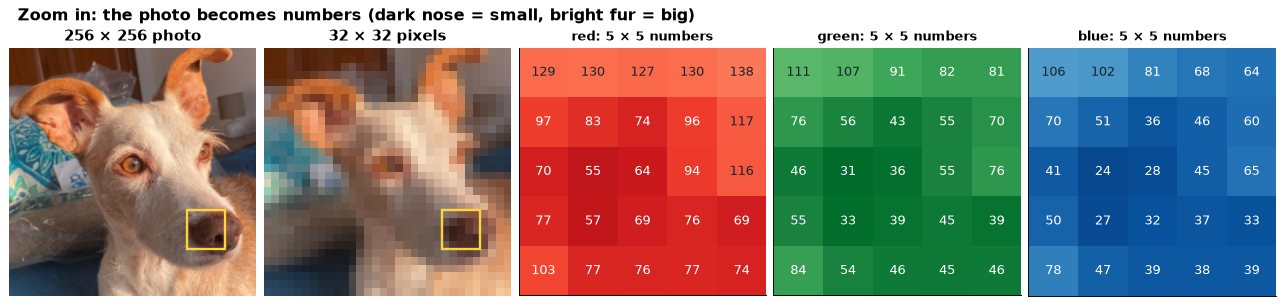

,height × width × channels,numbers
image,,
Fashion-MNIST item (grey),28 × 28 × 1,784
tiny colour photo,32 × 32 × 3,"3,072"
typical model input (colour),224 × 224 × 3,"150,528"
12-megapixel phone photo,"3,000 × 4,000 × 3","36,000,000"


In [7]:
tiny = np.asarray(dog.resize((32, 32), Image.BILINEAR))      # 32 × 32 × 3 = 3,072 numbers
r0, c0 = 21, 23                                              # top-left corner of a 5 × 5 patch around the nose
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), width_ratios=[1, 1, 1, 1, 1], layout="constrained")
axes[0].imshow(dog_np); axes[0].add_patch(Rectangle((c0 * 8 - .5, r0 * 8 - .5), 40, 40, fill=False, ec=YELLOW, lw=2))
axes[0].set_title("256 × 256 photo", loc="center")
axes[1].imshow(tiny); axes[1].add_patch(Rectangle((c0 - .5, r0 - .5), 5, 5, fill=False, ec=YELLOW, lw=2))
axes[1].set_title("32 × 32 pixels", loc="center")
for k, (name, cmap) in enumerate((("red", "Reds_r"), ("green", "Greens_r"), ("blue", "Blues_r"))):
    number_grid(axes[k + 2], tiny[r0:r0 + 5, c0:c0 + 5, k], cmap=cmap, vmin=0, vmax=255, fontsize=11,
                title=f"{name}: 5 × 5 numbers")
no_axes(axes[:2])
fig.suptitle("Zoom in: the photo becomes numbers (dark nose = small, bright fur = big)", x=0.01, ha="left", fontweight="bold")
show_jpeg(fig, quality=84)

sizes = {"Fashion-MNIST item (grey)": (28, 28, 1), "tiny colour photo": (32, 32, 3),
         "typical model input (colour)": (224, 224, 3), "12-megapixel phone photo": (3000, 4000, 3)}
pd.DataFrame([{"image": k, "height × width × channels": " × ".join(f"{v:,}" for v in s),
               "numbers": f"{np.prod(s):,}"} for k, s in sizes.items()]).set_index("image")

#### 🎛️ Try it: move the magnifying glass

Pick a row, a column and a channel: the 5 × 5 numbers under the yellow square update.

In [8]:
try:
    import ipywidgets as widgets

    def explore_pixels(row=21, col=23, channel="red"):
        k = ("red", "green", "blue", "grey").index(channel)
        grid = np.asarray(Image.fromarray(tiny).convert("L")) if k == 3 else tiny[..., k]
        fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
        a.imshow(tiny); a.add_patch(Rectangle((col - .5, row - .5), 5, 5, fill=False, ec=YELLOW, lw=2)); a.axis("off")
        number_grid(b, grid[row:row + 5, col:col + 5], cmap="gray", vmin=0, vmax=255, fontsize=11,
                    title=f"{channel}: rows {row}-{row + 4}, columns {col}-{col + 4}")
        plt.show()

    widgets.interact(explore_pixels, row=widgets.IntSlider(21, 0, 27), col=widgets.IntSlider(23, 0, 27),
                     channel=widgets.ToggleButtons(options=["red", "green", "blue", "grey"]))
except ImportError:
    print("ipywidgets is not installed: call explore_pixels(row, col, channel) by hand.")

interactive(children=(IntSlider(value=21, description='row', max=27), IntSlider(value=23, description='col', m…

### 💬 Discussion: is the computer "seeing"?

Look at the table of numbers of the boot without the picture next to it. Could you tell it is a boot? What would change in the numbers if the boot were **darker**, **smaller** or **moved to the left**?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

With the numbers only, you can still spot the shape because bright numbers cluster where the boot is, but it is slow and you rely on *neighbours*: a bright cell surrounded by bright cells. That is exactly what a convolution exploits later. Darker → all numbers smaller (models usually rescale to 0–1 to make this easier). Smaller or moved → the bright numbers land in *different* cells: for a model that reads cell 1, cell 2, … cell 784 in a fixed order (the MLP), it is a different input. Ask the class to keep this in mind for section 6.
</details>

<a id="sec-3"></a>
# 3. 👗 The task and the dataset: Fashion-MNIST

> 🎞️ **Slides:** [Image classification: one image in, one label out](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-task) · [Fashion-MNIST](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#fashion)

**The task.** One image in (a grid of numbers), **one probability per class** out, the biggest wins: the same softmax output as the MLP classifier of Lesson 02. It is ordinary supervised learning: the features are pixels, the target is the class. So we need many labelled images.

**The dataset.** **Fashion-MNIST** (Zalando Research, 2017) has 70,000 small grayscale photos of clothes from an online shop: 60,000 to train and 10,000 to test, 10 classes, perfectly balanced, 28 × 28 pixels. It was created as a harder drop-in replacement for the famous MNIST handwritten digits (same format), because digits had become too easy.

In [9]:
print("pixel values from", X_train_u8.min().item(), "to", X_train_u8.max().item())
counts = pd.Series(y_train.numpy()).value_counts().sort_index()
pd.DataFrame({"class": FASHION_CLASSES, "train images": counts.values}).T

pixel values from 0 to 255


,0,1,2,3,4,5,6,7,8,9
class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train images,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000


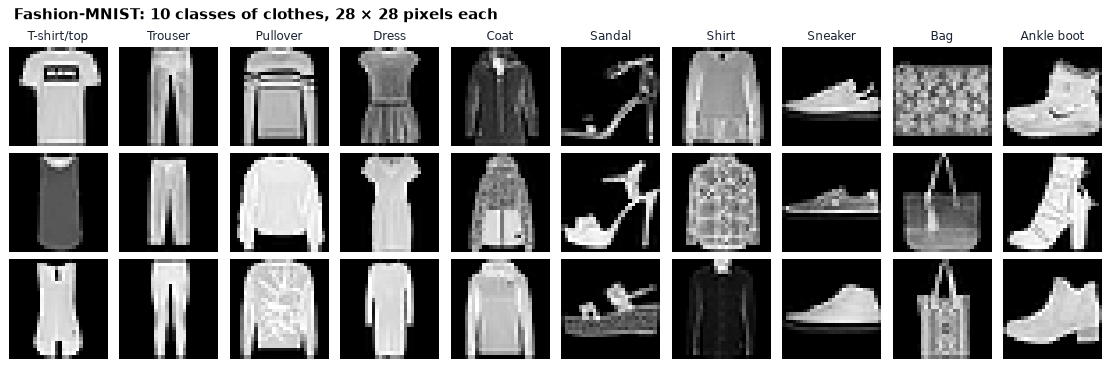

In [10]:
# Three examples of each class (columns = classes)
idx = [np.flatnonzero(y_train.numpy() == c)[k] for k in range(3) for c in range(10)]
titles = [FASHION_CLASSES[y_train[j]] if k < 10 else "" for k, j in enumerate(idx)]   # names on the first row
fig = show_grid([X_train_u8[j] for j in idx], titles=titles, ncols=10, size=1.3, cmap="gray",
                suptitle="Fashion-MNIST: 10 classes of clothes, 28 × 28 pixels each")
plt.show()

### 🧪 The "average" item of each class

Average the 6,000 training images of each class pixel by pixel: you get a ghost of the typical item. The second row shows where the images **disagree** (standard deviation): bright = this pixel changes a lot from one item to the next.

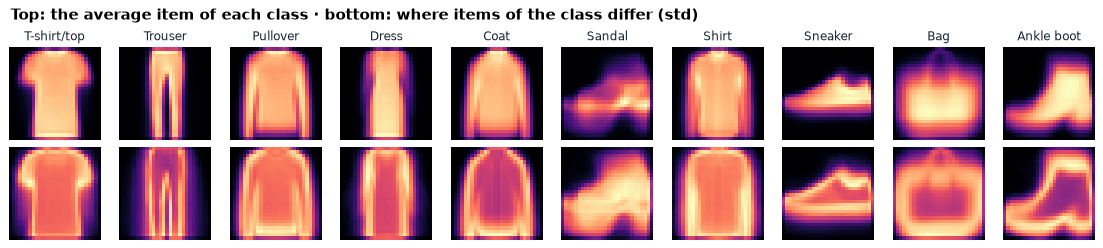

In [11]:
X_float = X_train_u8.float() / 255.0
means = torch.stack([X_float[y_train == c].mean(0) for c in range(10)])
stds = torch.stack([X_float[y_train == c].std(0) for c in range(10)])
fig = show_grid(list(means) + list(stds), titles=list(FASHION_CLASSES) + [""] * 10, ncols=10, size=1.3, cmap="magma",
                suptitle="Top: the average item of each class · bottom: where items of the class differ (std)")
plt.show()

The averages of **T-shirt/top, Pullover, Coat and Shirt** are almost the same blurry "something with sleeves". Let's look at real examples side by side: this is where every model will make most of its mistakes.

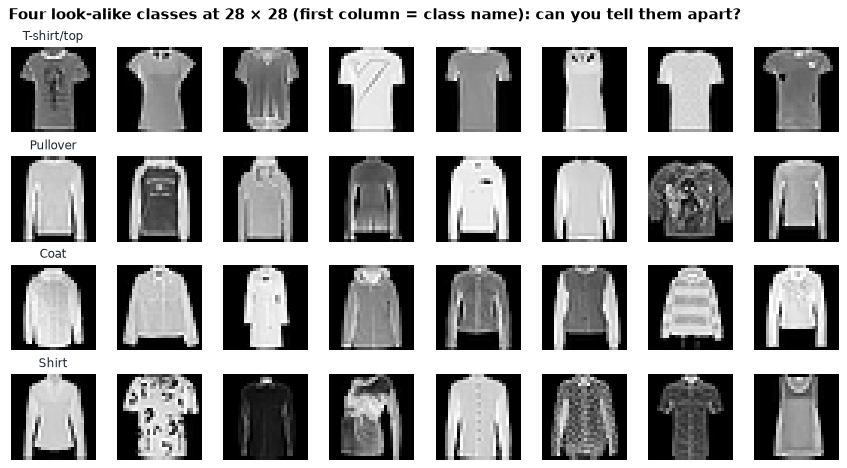

In [12]:
rng = np.random.default_rng(SEED)
lookalikes = [0, 2, 4, 6]                                     # T-shirt/top, Pullover, Coat, Shirt
picks = [rng.choice(np.flatnonzero(y_train.numpy() == c), 8, replace=False) for c in lookalikes]
images = [X_train_u8[j] for row in picks for j in row]
titles = [FASHION_CLASSES[c] if k == 0 else "" for c in lookalikes for k in range(8)]
fig = show_grid(images, titles=titles, ncols=8, size=1.25,
                suptitle="Four look-alike classes at 28 × 28 (first column = class name): can you tell them apart?")
plt.show()

<a id="sec-4"></a>
# 4. 📏 One item = 784 numbers

> 🎞️ **Slides:** [One item = 784 numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-784)

**Flatten** = put the 28 rows end to end: one row of 784 numbers. Row 14 of the image becomes positions 392 to 419 of the vector. A flat vector is exactly the kind of input the MLP of Lesson 02 takes.

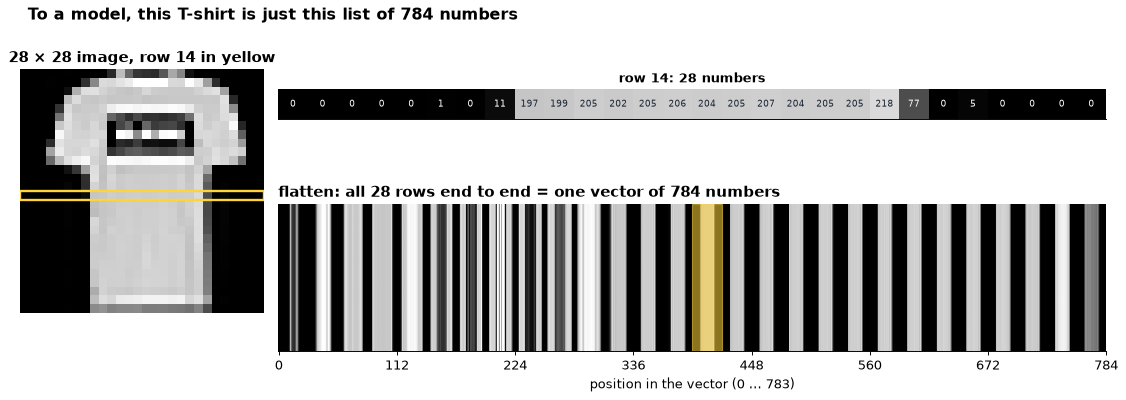

share of pixels that are exactly 0 (black background) in the training set: 50%


In [13]:
k, row = first[0], 14                                         # the first T-shirt, its row 14
tee = X_train_u8[k].numpy()
fig = plt.figure(figsize=(13, 4.6), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1, 3.4], height_ratios=[1, 1])
ax_img = fig.add_subplot(gs[:, 0]); ax_row = fig.add_subplot(gs[0, 1]); ax_vec = fig.add_subplot(gs[1, 1])
ax_img.imshow(tee, cmap="gray"); ax_img.add_patch(Rectangle((-.5, row - .5), 28, 1, fill=False, ec=YELLOW, lw=2))
ax_img.set_title("28 × 28 image, row 14 in yellow", loc="center"); ax_img.axis("off")
number_grid(ax_row, tee[row:row + 1], vmin=0, vmax=255, fontsize=7.5, title=f"row {row}: 28 numbers")
ax_vec.imshow(tee.reshape(1, 784), cmap="gray", aspect="auto", vmin=0, vmax=255)
ax_vec.axvspan(row * 28 - .5, row * 28 + 27.5, color=YELLOW, alpha=.55)
ax_vec.set_yticks([]); ax_vec.set_xticks(range(0, 785, 112)); ax_vec.grid(False)
ax_vec.set(xlabel="position in the vector (0 … 783)", title="flatten: all 28 rows end to end = one vector of 784 numbers")
fig.suptitle("To a model, this T-shirt is just this list of 784 numbers", x=0.01, ha="left", fontweight="bold")
plt.show()
print("share of pixels that are exactly 0 (black background) in the training set:",
      f"{(X_train_u8 == 0).float().mean():.0%}")

Stack the flat vectors of many images and you get **the table X of Lesson 02**: one row per image, one column per pixel. Here are 5 images of each class, one per row, sorted by class. You can already see "stripes" typical of each class.

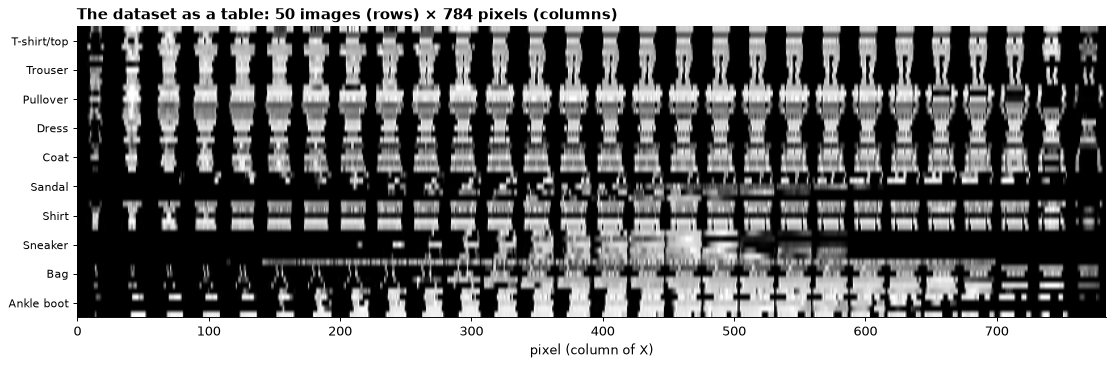

X for the whole training set: (60000, 784)


In [14]:
rows_idx = [np.flatnonzero(y_train.numpy() == c)[j] for c in range(10) for j in range(5)]
table = X_train_u8[rows_idx].reshape(len(rows_idx), 784).numpy()        # (50 images, 784 pixels)
fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
ax.imshow(table, cmap="gray", aspect="auto")
ax.set_yticks(np.arange(2, 50, 5), FASHION_CLASSES, fontsize=9); ax.grid(False)
ax.set(xlabel="pixel (column of X)", title="The dataset as a table: 50 images (rows) × 784 pixels (columns)")
show_jpeg(fig, quality=84)
print("X for the whole training set:", tuple(X_train_u8.reshape(len(X_train_u8), -1).shape))

<a id="sec-5"></a>
# 5. 🧮 First idea: flatten and feed the MLP

> 🎞️ **Slides:** [Remember the MLP? Flatten and feed it](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-mlp)

Same MLP, same training loop as Lesson 02; the only new thing is that the 784 inputs are pixels (scaled to 0–1). Every neuron is connected to every number of the layer before (*fully connected*). We can count its weights from the architecture alone, before any training:

In [15]:
sizes = [784, 256, 128, 10]
arch = pd.DataFrame([{"layer": f"{a} → {b}", "weights (a × b)": a * b, "biases (b)": b, "total": a * b + b}
                     for a, b in zip(sizes, sizes[1:])]).set_index("layer")
arch.loc["total"] = arch.sum()
arch.style.format("{:,}")

,weights (a × b),biases (b),total
layer,,,
784 → 256,"200,704",256,"200,960"
256 → 128,"32,768",128,"32,896"
128 → 10,"1,280",10,"1,290"
total,"234,752",394,"235,146"


**Three sets, like in Lesson 02.** We cut **10,000 validation images** out of the 60,000 training images. The **validation** set is used to watch the training and to compare the models; the official **test** set (10,000 images) stays locked until section 15, where we use it **once** for the final score.

| Set | Images | Used for |
|---|---|---|
| train | 50,000 | learning the weights |
| validation | 10,000 | curves per epoch, comparing models, the shift test, looking inside |
| test | 10,000 | the final exam, once, at the end |

> ⚠️ **Watch out:** the **evaluation loaders never shuffle**. We compare predictions with labels by position; shuffling only the predictions (or only the labels) is a classic silent bug that makes a good model look random.

In [16]:
X_train = X_train_u8[:, None].float() / 255.0          # (60000, 1, 28, 28), values 0..1
X_test = X_test_u8[:, None].float() / 255.0
perm = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(SEED))
val_idx, tr_idx = perm[:10_000], perm[10_000:]          # random 10,000 for validation, 50,000 to train
X_val, y_val = X_train[val_idx], y_train[val_idx]
X_val_u8 = X_train_u8[val_idx]

def eval_loader(x, y, batch_size=1000):
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=False)   # fixed order!

train_dl = DataLoader(TensorDataset(X_train[tr_idx], y_train[tr_idx]), batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = eval_loader(X_val, y_val)
test_dl = eval_loader(X_test, y_test)                   # locked until section 15
print("train:", len(tr_idx), "| validation:", len(val_idx), "| test:", len(X_test),
      "| validation images per class:", np.bincount(y_val.numpy()).min(), "to", np.bincount(y_val.numpy()).max())
EPOCHS = 4

def make_mlp():
    return nn.Sequential(
        nn.Flatten(),                              # (batch, 1, 28, 28) -> (batch, 784)
        nn.Linear(784, 256), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, 10),                        # 10 logits; the cross-entropy loss applies the softmax
    )

set_seed(SEED)
mlp = make_mlp()
print(f"MLP parameters: {count_parameters(mlp):,} (the same number as the table above)")
hist_mlp = train_model(mlp, train_dl, val_dl, epochs=EPOCHS, lr=2e-3)
res_mlp = evaluate(mlp, val_dl)
print(f"MLP validation accuracy: {res_mlp['accuracy']:.1%}  (guessing at random: 10%)")

train: 50000 | validation: 10000 | test: 10000 | validation images per class: 957 to 1061
MLP parameters: 235,146 (the same number as the table above)


epoch  1/4: train loss 0.546 acc 0.804 | val loss 0.412 acc 0.848 | 1.2 s


epoch  2/4: train loss 0.383 acc 0.861 | val loss 0.381 acc 0.858 | 1.4 s


epoch  3/4: train loss 0.339 acc 0.875 | val loss 0.353 acc 0.871 | 2.0 s


epoch  4/4: train loss 0.315 acc 0.885 | val loss 0.375 acc 0.858 | 1.9 s
MLP validation accuracy: 85.8%  (guessing at random: 10%)


### 🎯 One image in, ten probabilities out

That is the whole task from the slides, now with real numbers: a validation image goes in, the softmax gives one probability per class, the biggest wins.

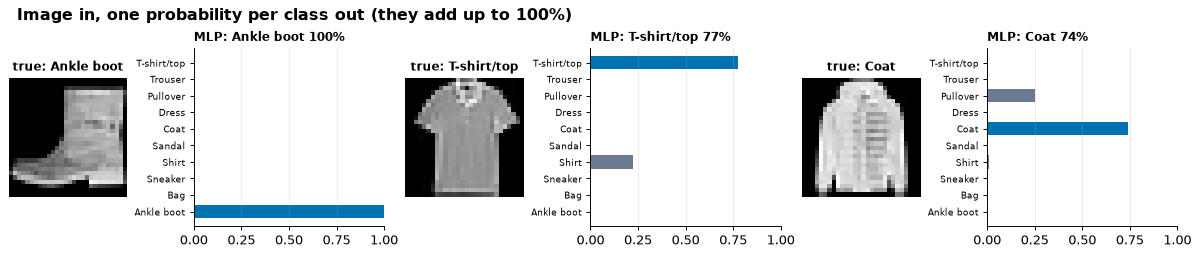

In [17]:
fig, axes = plt.subplots(1, 6, figsize=(14, 2.9), width_ratios=[1, 1.6, 1, 1.6, 1, 1.6], layout="constrained")
for (a_img, a_bar), j in zip(axes.reshape(3, 2), [0, 3, 11]):
    p = res_mlp["proba"][j]
    a_img.imshow(X_val_u8[j], cmap="gray"); a_img.axis("off")
    a_img.set_title(f"true: {FASHION_CLASSES[y_val[j]]}", loc="center", fontsize=10)
    colours = [PALETTE["blue"] if c == p.argmax() else PALETTE["grey"] for c in range(10)]
    a_bar.barh(range(10), p, color=colours); a_bar.set_yticks(range(10), FASHION_CLASSES, fontsize=8)
    a_bar.invert_yaxis(); a_bar.set_xlim(0, 1); a_bar.grid(axis="y", visible=False)
    a_bar.set_title(f"MLP: {FASHION_CLASSES[p.argmax()]} {p.max():.0%}", loc="left", fontsize=10)
fig.suptitle("Image in, one probability per class out (they add up to 100%)", x=0.01, ha="left", fontweight="bold")
plt.show()

## 🧠 What did the MLP's first layer learn?

Each of the 256 neurons of the first layer has **784 weights, one per pixel**. Put them back into a 28 × 28 grid and you can *see* what the neuron is looking for: **red** pixels push the neuron up, **blue** pixels push it down. Several look like blurry **outlines**: two trouser legs, the sole of a shoe, the shoulders and sleeves of a top. The MLP learned *where* light and dark pixels usually are: at **fixed positions**.

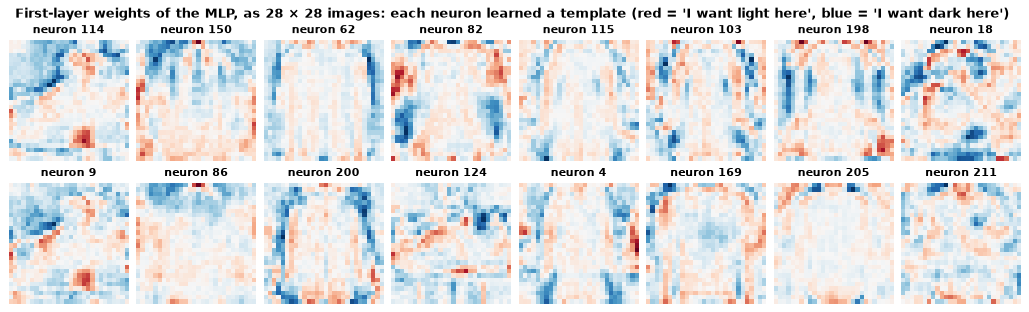

In [18]:
W = mlp[1].weight.detach().numpy()                     # (256, 784)
strongest = np.argsort(-np.abs(W).sum(1))[:16]         # the 16 neurons with the largest weights
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6), layout="constrained")
for ax, k in zip(axes.ravel(), strongest):
    w = W[k].reshape(28, 28); lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off"); ax.set_title(f"neuron {k}", fontsize=9, loc="center")
fig.suptitle("First-layer weights of the MLP, as 28 × 28 images: each neuron learned a template "
             "(red = 'I want light here', blue = 'I want dark here')", x=0.01, ha="left", fontsize=11, fontweight="bold")
save_slide(fig, "cv-mlp-weights.png")
plt.show()

<a id="sec-6"></a>
# 6. 🧩 The problem: flattening forgets the neighbours

> 🎞️ **Slides:** [Flattening forgets the neighbours](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-flat)

Three problems, three experiments:

1. Pixels that touch in the image end up **28 positions apart** in the vector. The MLP is never told who is next to whom.
2. Move the same T-shirt a little and **hundreds of inputs change**: for the MLP it is a different picture.
3. Big photos explode: a 224 × 224 colour photo has 150,528 inputs, so **150,528 weights per neuron**.

In [19]:
r, c = 10, 5
print(f"pixel (row {r}, col {c}) -> position {r * 28 + c} | its neighbour below (row {r + 1}, col {c}) -> "
      f"position {(r + 1) * 28 + c}: 28 positions apart")
print(f"weights of ONE first-layer neuron on a 224 × 224 colour photo: {224 * 224 * 3:,} (+ 1 bias)")

pixel (row 10, col 5) -> position 285 | its neighbour below (row 11, col 5) -> position 313: 28 positions apart
weights of ONE first-layer neuron on a 224 × 224 colour photo: 150,528 (+ 1 bias)


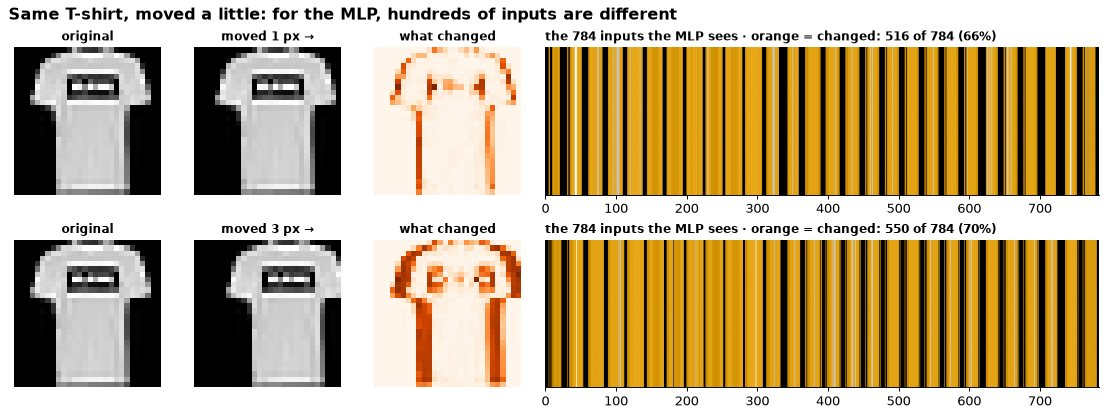

In [20]:
tee_t = torch.tensor(tee)
fig = plt.figure(figsize=(13, 4.8), layout="constrained")
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 3.2])
for row_i, px in enumerate((1, 3)):
    moved = shift_images(tee_t, dx=px).numpy()
    changed = tee.ravel() != moved.ravel()
    panels = [(tee, "original"), (moved, f"moved {px} px →"), (np.abs(moved.astype(int) - tee), "what changed")]
    for col_i, (arr, title) in enumerate(panels):
        ax = fig.add_subplot(gs[row_i, col_i]); ax.imshow(arr, cmap="gray" if col_i < 2 else "Oranges"); ax.axis("off")
        ax.set_title(title, loc="center", fontsize=10)
    ax = fig.add_subplot(gs[row_i, 3])
    strip = np.where(changed, 1.0, np.nan).reshape(1, 784)
    ax.imshow(moved.reshape(1, 784), cmap="gray", aspect="auto")
    ax.imshow(strip, cmap=mpl.colors.ListedColormap([PALETTE["orange"]]), aspect="auto", alpha=.9)
    ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"the 784 inputs the MLP sees · orange = changed: {changed.sum()} of 784 ({changed.mean():.0%})",
                 loc="left", fontsize=10)
fig.suptitle("Same T-shirt, moved a little: for the MLP, hundreds of inputs are different", x=0.01, ha="left", fontweight="bold")
show_jpeg(fig, quality=84)

### 🧪 Experiment 1: move every validation image a few pixels

Same clothes, same trained MLP. We move all 10,000 validation images 1, 2, 3 and 4 pixels to the right (the empty columns become black) and measure the accuracy again.

MLP accuracy: 85.8% on the validation images -> 32.0% with the same images moved 3 px


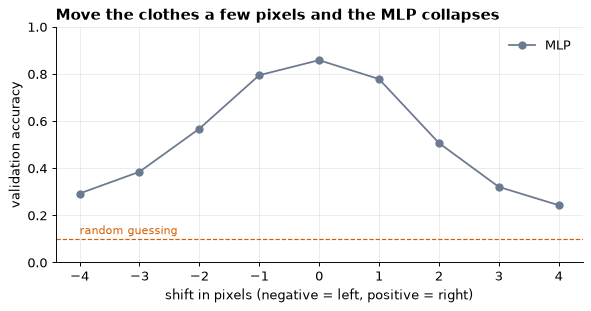

In [21]:
SHIFTS = [-4, -3, -2, -1, 0, 1, 2, 3, 4]                # negative = to the left
def shift_curve(model):
    return [evaluate(model, eval_loader(shift_images(X_val, dx=s), y_val))["accuracy"] for s in SHIFTS]

shift_mlp = shift_curve(mlp)
acc_mlp_shift = shift_mlp[SHIFTS.index(3)]
print(f"MLP accuracy: {res_mlp['accuracy']:.1%} on the validation images -> {acc_mlp_shift:.1%} with the same images moved 3 px")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(SHIFTS, shift_mlp, marker="o", color=PALETTE["grey"], label="MLP")
ax.axhline(0.1, color=PALETTE["red"], ls="--", lw=1); ax.text(-4, 0.12, "random guessing", color=PALETTE["red"], fontsize=9)
ax.set(xlabel="shift in pixels (negative = left, positive = right)", ylabel="validation accuracy", ylim=(0, 1),
       title="Move the clothes a few pixels and the MLP collapses")
ax.legend(); plt.show()

### 🧪 Experiment 2: shuffle the pixels

If the MLP does not know who is next to whom, it should not care if we **shuffle the pixels**, as long as we always shuffle them **the same way**. We pick one fixed random order of the 784 positions, apply it to every image (train and validation), and train a fresh MLP. To us the images become noise.

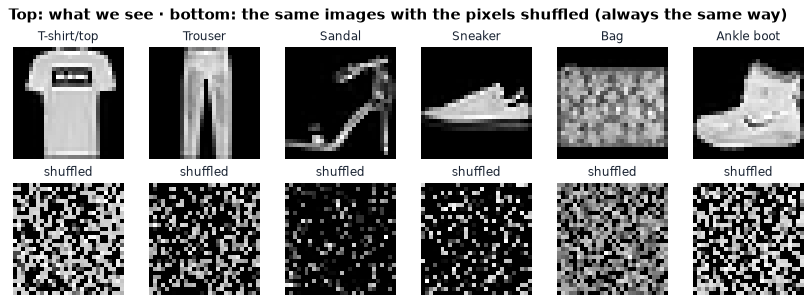

MLP on normal images: 85.8% | a new MLP trained and tested on shuffled images: 88.2%


In [22]:
pixel_order = torch.randperm(784, generator=torch.Generator().manual_seed(SEED))   # ONE fixed shuffle for all images

def shuffle_pixels(x):
    return x.reshape(len(x), 1, 784)[..., pixel_order].reshape(len(x), 1, 28, 28)

examples = [first[c] for c in (0, 1, 5, 7, 8, 9)]
fig = show_grid([X_train[j, 0] for j in examples] + [shuffle_pixels(X_train[j:j + 1])[0, 0] for j in examples],
                titles=[FASHION_CLASSES[y_train[j]] for j in examples] + ["shuffled"] * 6, ncols=6, size=1.6,
                suptitle="Top: what we see · bottom: the same images with the pixels shuffled (always the same way)")
plt.show()

set_seed(SEED)
mlp_shuffled = make_mlp()
train_model(mlp_shuffled, train_dl, val_dl, epochs=EPOCHS, lr=2e-3, input_fn=shuffle_pixels, verbose=False)
acc_mlp_shuffled = evaluate(mlp_shuffled, val_dl, input_fn=shuffle_pixels)["accuracy"]
print(f"MLP on normal images: {res_mlp['accuracy']:.1%} | a new MLP trained and tested on shuffled images: {acc_mlp_shuffled:.1%}")

The shuffled MLP is just as good: the **order of the pixels carries no information for an MLP**. That is the problem in one number: the most useful thing about an image, which pixels are neighbours, is thrown away by flattening. We want a model that knows about neighbourhoods, does not care much *where* the object is, and uses few weights.

<a id="sec-7"></a>
# 7. 💡 A better idea: look at small patches

> 🎞️ **Slides:** [Convolutional neural networks: look at small patches](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-cnnidea)

Three ideas, one per problem:

| Idea | Fixes |
|---|---|
| 🔍 **Look locally**: each unit looks at a small patch (e.g. 3 × 3 pixels) | neighbours stay together |
| ♻️ **Reuse everywhere**: the same small detector scans the whole image | few weights; an edge is an edge wherever it is |
| 🧱 **Build up**: simple patterns are combined, layer after layer, into bigger ones | complex objects from simple parts |

The idea is old and inspired by biology: **1959** Hubel & Wiesel find brain cells that react to edges in small regions · **1980** Fukushima's Neocognitron · **1989** LeCun trains a CNN with backprop to read ZIP codes · **1998** LeNet-5 reads cheques · **2012** AlexNet wins ImageNet (section 15).

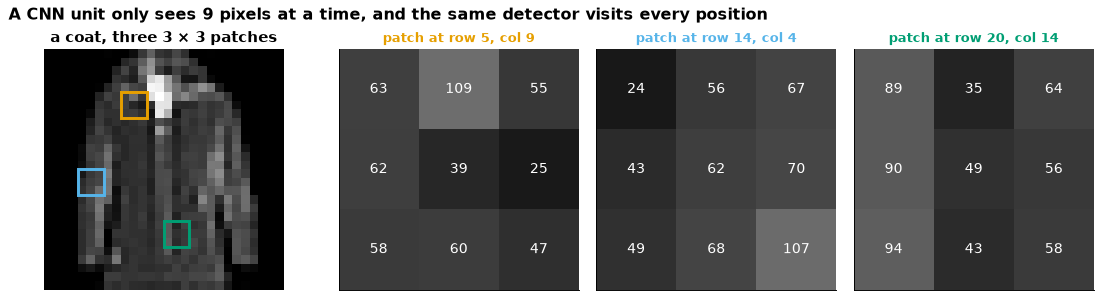

In [23]:
coat = X_train_u8[first[4]].numpy()
spots = [(5, 9), (14, 4), (20, 14)]                       # (row, col) of the top-left corner of three 3 × 3 patches
colours = [PALETTE["orange"], PALETTE["sky"], PALETTE["green"]]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), width_ratios=[1.3, 1, 1, 1], layout="constrained")
axes[0].imshow(coat, cmap="gray"); axes[0].axis("off"); axes[0].set_title("a coat, three 3 × 3 patches", loc="center")
for ax, (r, c), colour in zip(axes[1:], spots, colours):
    axes[0].add_patch(Rectangle((c - .5, r - .5), 3, 3, fill=False, ec=colour, lw=2.5))
    number_grid(ax, coat[r:r + 3, c:c + 3], vmin=0, vmax=255, fontsize=12)
    ax.set_title(f"patch at row {r}, col {c}", loc="center", color=colour, fontsize=11)
fig.suptitle("A CNN unit only sees 9 pixels at a time, and the same detector visits every position",
             x=0.01, ha="left", fontweight="bold")
plt.show()

<a id="sec-8"></a>
# 8. ✖️ A kernel: multiply, then add

> 🎞️ **Slides:** [A kernel: multiply, then add](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-kernel)

## 🧠 How it works: the sliding magnifying glass

**Simple idea.** A **kernel** (or filter) is a tiny grid of weights, here 3 × 3. Put it on a 3 × 3 patch of the image, multiply cell by cell, add the 9 results: **one number**.

**Steps:** (1) choose a kernel (here, by hand: a *vertical edge detector*, −1 on the left, +1 on the right); (2) put it on a patch; (3) multiply and sum; (4) big answer = "the pattern is here".

**Analogy.** A magnifying glass that only lights up when it is on top of a vertical edge.

**Limits.** One kernel finds one simple pattern. In a CNN nobody chooses these 9 numbers: they are weights, **learned** by training like any other weight.

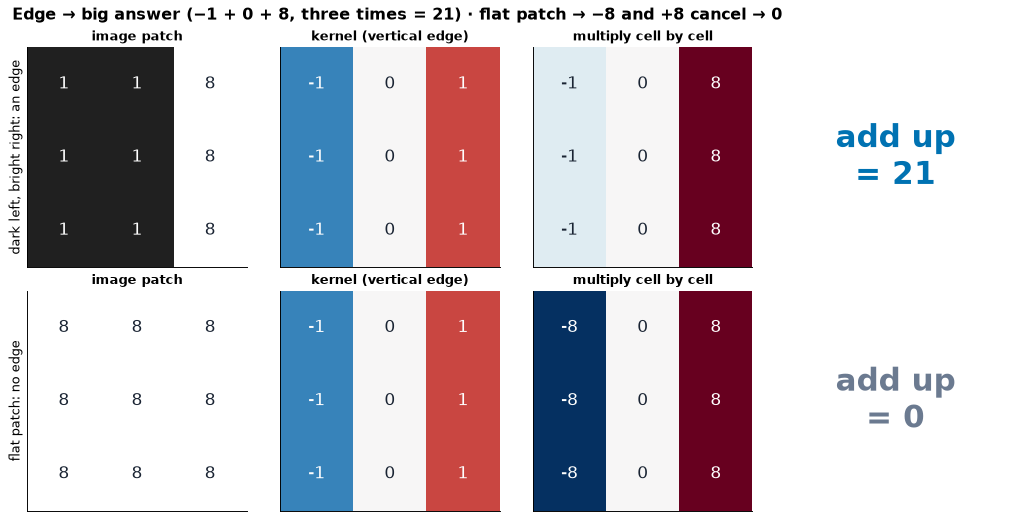

In [24]:
edge_kernel = np.array([[-1, 0, 1]] * 3, dtype=np.float32)        # the kernel of the slides
cases = {"dark left, bright right: an edge": np.array([[1, 1, 8]] * 3, dtype=np.float32),
         "flat patch: no edge": np.full((3, 3), 8, dtype=np.float32)}
fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for row, (name, patch) in enumerate(cases.items()):
    products = patch * edge_kernel
    number_grid(axes[row, 0], patch, vmin=0, vmax=8, fontsize=14, title="image patch")
    number_grid(axes[row, 1], edge_kernel, cmap="RdBu_r", vmin=-1.5, vmax=1.5, fontsize=14, title="kernel (vertical edge)")
    number_grid(axes[row, 2], products, cmap="RdBu_r", vmin=-8, vmax=8, fontsize=14, title="multiply cell by cell")
    axes[row, 3].text(0.5, 0.5, f"add up\n= {products.sum():.0f}", ha="center", va="center", fontsize=26, fontweight="bold",
                      color=PALETTE["blue"] if products.sum() else PALETTE["grey"])
    axes[row, 3].axis("off"); axes[row, 0].set_ylabel(name)
fig.suptitle("Edge → big answer (−1 + 0 + 8, three times = 21) · flat patch → −8 and +8 cancel → 0", x=0.01, ha="left", fontweight="bold")
plt.show()

Now on real pixels: a 3 × 3 patch of our ankle boot (values 0–1), multiplied and summed by hand, and the same operation done by PyTorch's `conv2d` at that position.

In [25]:
kernel = KERNELS["vertical edges"]                 # Sobel filter: the same idea, with a stronger middle row
img01 = X_train[i, 0].numpy()                      # our ankle boot, values 0..1
r, c = 14, 8                                       # one position in the image
patch = img01[r - 1:r + 2, c - 1:c + 2]
by_hand = (patch * kernel).sum()                   # multiply pixel by weight, then add the 9 numbers
fmap = apply_kernel(img01, kernel)                 # the same operation at every position (PyTorch conv2d)

print("3 × 3 patch of pixels around (row 14, col 8):\n", patch.round(2))
print("kernel (vertical edge detector):\n", kernel.astype(int))
print(f"multiply + sum by hand = {by_hand:.3f} | conv2d at the same position = {fmap[r, c]:.3f}")

3 × 3 patch of pixels around (row 14, col 8):
 [[0.   0.   0.02]
 [0.   0.   0.  ]
 [0.   0.   0.24]]
kernel (vertical edge detector):
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
multiply + sum by hand = 0.259 | conv2d at the same position = 0.259


<a id="sec-9"></a>
# 9. 🎞️ Slide the kernel: a feature map

> 🎞️ **Slides:** [Slide the kernel → a feature map](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-conv)

Slide the kernel one pixel at a time, left to right, top to bottom; each position gives **one** output number. All the numbers together form a new image: the **feature map** ("where in the image is this pattern?"). Below, a 12 × 12 piece of a real sneaker: a 3 × 3 window fits 10 times along each side, so the map is 10 × 10 (with *padding*, a border of zeros, it would keep the size). Orange = dark turns bright from left to right, blue = bright turns dark, white = flat.

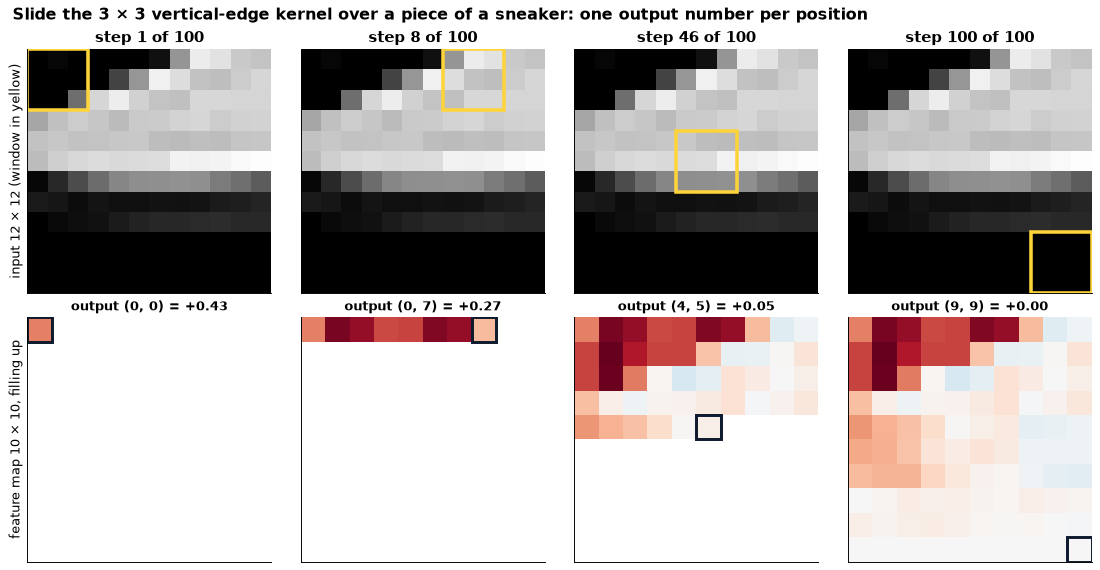

In [26]:
sneaker = X_train[first[7], 0].numpy()
piece = sneaker[12:24, 4:16]                                      # a 12 × 12 piece of the sneaker
fmap_small = F.conv2d(torch.tensor(piece)[None, None], torch.tensor(edge_kernel)[None, None])[0, 0].numpy()  # 10 × 10
lim = np.abs(fmap_small).max()
steps = [0, 7, 45, 99]                                            # which positions to show (of 10 × 10 = 100)
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6), layout="constrained")
for col, s in enumerate(steps):
    r, c = divmod(s, 10)
    axes[0, col].imshow(piece, cmap="gray", vmin=0, vmax=1)
    axes[0, col].add_patch(Rectangle((c - .5, r - .5), 3, 3, fill=False, ec=YELLOW, lw=3))
    axes[0, col].set_title(f"step {s + 1} of 100", loc="center")
    partial = np.full((10, 10), np.nan); partial.flat[:s + 1] = fmap_small.flat[:s + 1]
    axes[1, col].imshow(partial, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[1, col].add_patch(Rectangle((c - .5, r - .5), 1, 1, fill=False, ec=PALETTE["navy"], lw=2.5))
    axes[1, col].set_title(f"output ({r}, {c}) = {fmap_small[r, c]:+.2f}", loc="center", fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0, 0].set_ylabel("input 12 × 12 (window in yellow)"); axes[1, 0].set_ylabel("feature map 10 × 10, filling up")
fig.suptitle("Slide the 3 × 3 vertical-edge kernel over a piece of a sneaker: one output number per position",
             x=0.01, ha="left", fontweight="bold")
plt.show()

#### 🎛️ Try it: slide the kernel yourself

Choose a clothing item, a kernel and a step: you see the window, the 9 products and the feature map filling up (26 × 26 for a 28 × 28 image without padding).

In [27]:
try:
    import ipywidgets as widgets
    SIMPLE = {"vertical edge": edge_kernel, "horizontal edge": edge_kernel.T.copy(),
              "blur": np.full((3, 3), 1 / 9, dtype=np.float32), "sharpen": KERNELS["sharpen"]}

    def slide(item="Sneaker", kernel_name="vertical edge", step=300):
        x = X_train[first[FASHION_CLASSES.index(item)], 0].numpy()
        k = SIMPLE[kernel_name]
        full = F.conv2d(torch.tensor(x)[None, None], torch.tensor(k)[None, None])[0, 0].numpy()   # 26 × 26
        r, c = divmod(step, 26)
        fig, (a, b, m) = plt.subplots(1, 3, figsize=(12, 3.8), width_ratios=[1, 1, 1], layout="constrained")
        a.imshow(x, cmap="gray"); a.add_patch(Rectangle((c - .5, r - .5), 3, 3, fill=False, ec=YELLOW, lw=2.5)); a.axis("off")
        number_grid(b, x[r:r + 3, c:c + 3] * k, cmap="RdBu_r", vmin=-1, vmax=1, fmt="{:+.2f}", fontsize=10,
                    title=f"9 products, sum = {full[r, c]:+.2f}")
        part = np.full(full.shape, np.nan); part.flat[:step + 1] = full.flat[:step + 1]
        lim_ = max(np.abs(full).max(), 1e-6)
        m.imshow(part, cmap="RdBu_r" if kernel_name != "blur" else "magma", vmin=-lim_ if kernel_name != "blur" else 0, vmax=lim_)
        m.set_title(f"feature map, step {step + 1} of 676", loc="center"); m.axis("off")
        plt.show()

    widgets.interact(slide, item=widgets.Dropdown(options=list(FASHION_CLASSES), value="Sneaker"),
                     kernel_name=widgets.ToggleButtons(options=list(SIMPLE)),
                     step=widgets.IntSlider(300, 0, 675, continuous_update=False))
except ImportError:
    print("ipywidgets is not installed: call slide(item, kernel_name, step) by hand.")

interactive(children=(Dropdown(description='item', index=7, options=('T-shirt/top', 'Trouser', 'Pullover', 'Dr…

### 🐱 The same kernels on a real photo

Kernels do not care what the image shows: here are hand-made kernels on one of our test pets (in grey). Edge kernels make whiskers, eyes and ears pop out; blur averages neighbours; sharpen exaggerates differences.

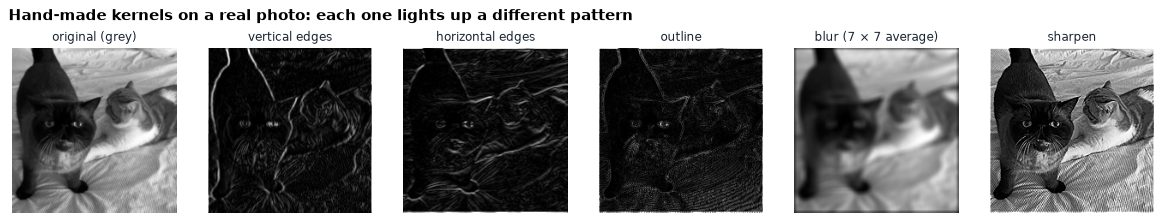

In [28]:
cat = np.asarray(resize_center_crop(load_image(PETS / "cats" / "cat9003.jpg"), 192).convert("L"), dtype=np.float32) / 255
photo_kernels = {"vertical edges": KERNELS["vertical edges"], "horizontal edges": KERNELS["horizontal edges"],
                 "outline": KERNELS["outline"], "blur (7 × 7 average)": np.full((7, 7), 1 / 49, dtype=np.float32),
                 "sharpen": KERNELS["sharpen"]}
outs = [cat] + [apply_kernel(cat, k) for k in photo_kernels.values()]
names_photo = ["original"] + list(photo_kernels)
# edge maps: show the strength |output|, scaled so the strongest 0.5 % of pixels are white (otherwise a few
# very bright pixels make everything else look black); the others are images already: just keep 0..1
shown = [np.clip(np.abs(o) / max(np.percentile(np.abs(o), 99.5), 1e-6), 0, 1) if "edges" in n or n == "outline"
         else np.clip(o, 0, 1) for n, o in zip(names_photo, outs)]
fig = show_grid(shown, ["original (grey)"] + list(photo_kernels),
                ncols=6, size=2.3, suptitle="Hand-made kernels on a real photo: each one lights up a different pattern")
save_slide(fig, "cv-kernel-on-pet.webp")
show_jpeg(fig)

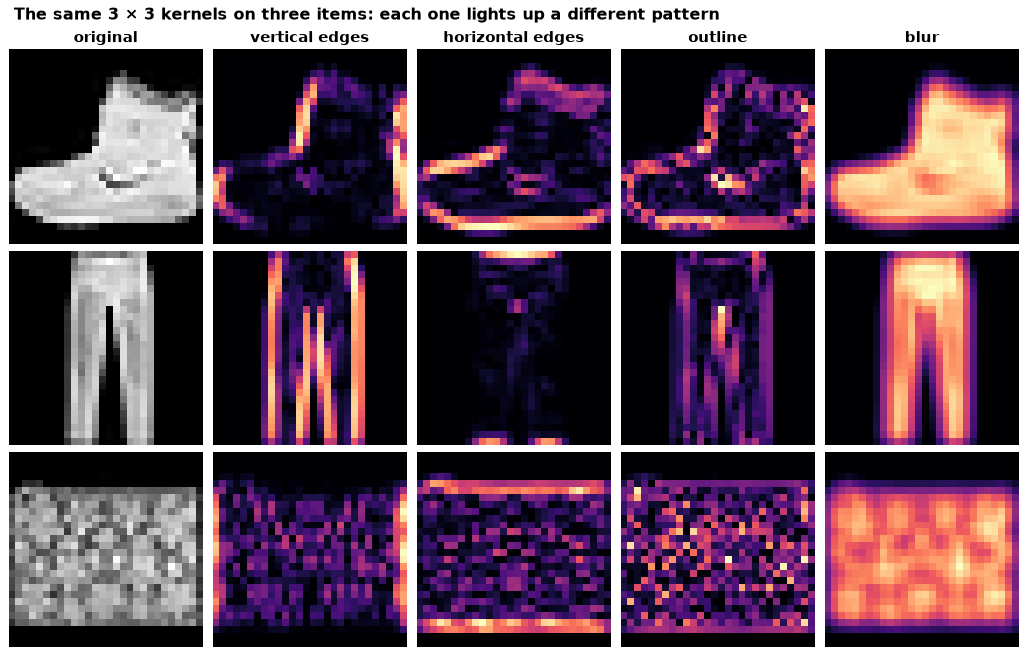

In [29]:
names = ["vertical edges", "horizontal edges", "outline", "blur"]
samples = [i, first[1], first[8]]
fig, axes = plt.subplots(len(samples), 1 + len(names), figsize=(12, 7.6), layout="constrained")
for row, j in enumerate(samples):
    x = X_train[j, 0].numpy()
    axes[row, 0].imshow(x, cmap="gray"); axes[row, 0].set_title("original" if row == 0 else "", loc="center")
    for col, name in enumerate(names, start=1):
        out = apply_kernel(x, KERNELS[name])
        axes[row, col].imshow(np.abs(out) if "edges" in name or name == "outline" else out, cmap="magma")
        if row == 0:
            axes[row, col].set_title(name, loc="center")
no_axes(axes)
fig.suptitle("The same 3 × 3 kernels on three items: each one lights up a different pattern", x=0.01, ha="left", fontweight="bold")
plt.show()

### 💬 Discussion: who designs the kernels?

We wrote the edge detector by hand. Before 2012, computer vision engineers did exactly that: they designed filters for edges, corners, textures… What is the problem with that approach, and what does a CNN do differently?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Hand-made filters only find what the engineer thought of, and they break when the lighting, the angle or the object changes. A CNN starts with **random** kernels and **learns** their 9 weights with backprop, the same way the MLP learned its weights in Lesson 02. The first layer usually ends up with edge and colour detectors (like ours: we will see them in section 14), deeper layers with textures and parts. AlexNet (2012) showed that learned filters beat years of hand-made ones on ImageNet.
</details>

<a id="sec-10"></a>
# 10. 🗂️ Many kernels, many feature maps

> 🎞️ **Slides:** [Convolution gives us a lot of numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-many)

One kernel gives one feature map. A real layer has **many** kernels (32, 64…), each looking for a different pattern, so one image becomes many maps. With padding every map is as big as the image. Here are 8 different 3 × 3 kernels on the same ankle boot:

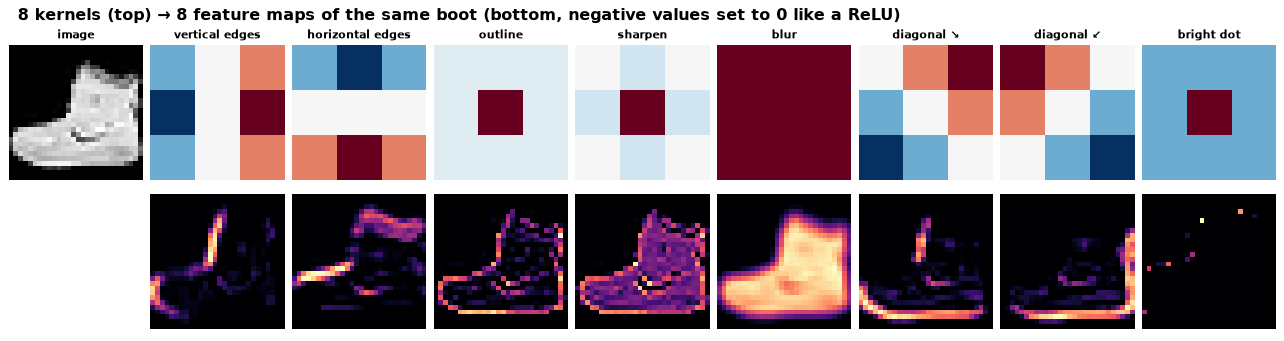

In [30]:
bank = {**{k: KERNELS[k] for k in ("vertical edges", "horizontal edges", "outline", "sharpen", "blur")},
        "diagonal ↘": np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]], dtype=np.float32),
        "diagonal ↙": np.array([[2, 1, 0], [1, 0, -1], [0, -1, -2]], dtype=np.float32),
        "bright dot": np.array([[-1, -1, -1], [-1, 2, -1], [-1, -1, -1]], dtype=np.float32) / 2}
fig, axes = plt.subplots(2, 9, figsize=(15, 3.9), layout="constrained")
for col, (name, k) in enumerate(bank.items(), start=1):
    lim_k = np.abs(k).max()
    axes[0, col].imshow(k, cmap="RdBu_r", vmin=-lim_k, vmax=lim_k); axes[0, col].set_title(name, loc="center", fontsize=9)
    axes[1, col].imshow(np.maximum(apply_kernel(img01, k), 0), cmap="magma")
axes[0, 0].imshow(img01, cmap="gray"); axes[0, 0].set_title("image", loc="center", fontsize=9)
axes[1, 0].axis("off")
no_axes(axes)
fig.suptitle("8 kernels (top) → 8 feature maps of the same boot (bottom, negative values set to 0 like a ReLU)",
             x=0.01, ha="left", fontweight="bold")
plt.show()

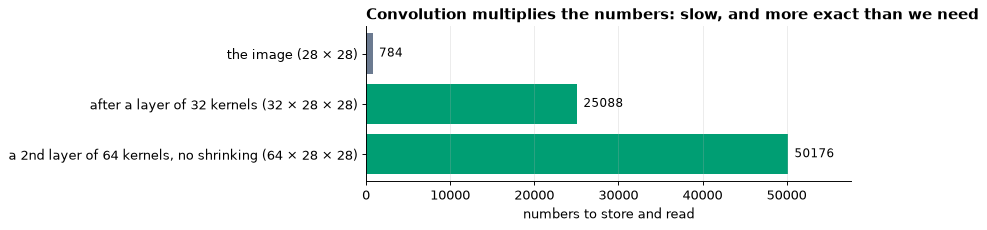

In [31]:
counts = {"the image (28 × 28)": 28 * 28,
          "after a layer of 32 kernels (32 × 28 × 28)": 32 * 28 * 28,
          "a 2nd layer of 64 kernels, no shrinking (64 × 28 × 28)": 64 * 28 * 28}
fig, ax = plt.subplots(figsize=(10, 2.6), layout="constrained")
ax.barh(range(3), list(counts.values()), color=[PALETTE["grey"], PALETTE["green"], PALETTE["green"]])
ax.set_yticks(range(3), list(counts)); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
label_bars(ax, list(counts.values()), decimals=0)
ax.set(xlabel="numbers to store and read", title="Convolution multiplies the numbers: slow, and more exact than we need")
plt.show()

Two problems: it is **slow** (every next layer must read all these numbers) and **too exact** (we do not need the exact pixel of an edge: "there is a heel around here" is enough). So: shrink each map, keeping only the strongest signal of each small area. That is **pooling**.

<a id="sec-11"></a>
# 11. 🔽 Pooling: shrink, keep the strongest

> 🎞️ **Slides:** [Pooling: shrink, keep the strongest](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-pool)

## 🧠 How it works: max-pooling

**Simple idea.** Cut the feature map into 2 × 2 blocks and keep only the **biggest** number of each block. The map becomes 4× smaller (28 × 28 × 32 = 25,088 → 14 × 14 × 32 = 6,272 numbers).

**Why it helps.** It keeps "the pattern is around here" and forgets the exact pixel, so a pattern moved by one pixel often gives the same result. It has **no weights**: it is a fixed rule.

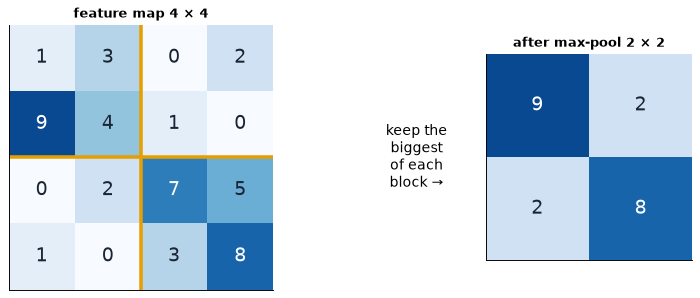

In [32]:
toy = np.array([[1, 3, 0, 2], [9, 4, 1, 0], [0, 2, 7, 5], [1, 0, 3, 8]], dtype=np.float32)
pooled_toy = F.max_pool2d(torch.tensor(toy)[None, None], 2)[0, 0].numpy()
fig, (a, arrow, b) = plt.subplots(1, 3, figsize=(9, 3.4), width_ratios=[2, 0.6, 1], layout="constrained")
number_grid(a, toy, cmap="Blues", vmin=0, vmax=10, fontsize=16, title="feature map 4 × 4")
for t in (1.5,):
    a.axhline(t, color=PALETTE["orange"], lw=3); a.axvline(t, color=PALETTE["orange"], lw=3)
number_grid(b, pooled_toy, cmap="Blues", vmin=0, vmax=10, fontsize=16, title="after max-pool 2 × 2")
arrow.text(0.5, 0.5, "keep the\nbiggest\nof each\nblock →", ha="center", va="center", fontsize=12); arrow.axis("off")
plt.show()

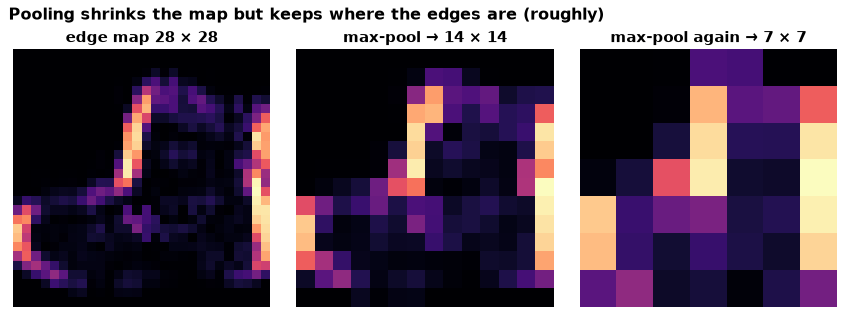

In [33]:
edges = np.abs(apply_kernel(img01, KERNELS["vertical edges"]))
pooled = F.max_pool2d(torch.tensor(edges)[None, None], 2)[0, 0].numpy()
pooled2 = F.max_pool2d(torch.tensor(pooled)[None, None], 2)[0, 0].numpy()
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), layout="constrained")
for ax, m, t in zip(axes, (edges, pooled, pooled2), ("edge map 28 × 28", "max-pool → 14 × 14", "max-pool again → 7 × 7")):
    ax.imshow(m, cmap="magma"); ax.set_title(t, loc="center"); ax.axis("off")
fig.suptitle("Pooling shrinks the map but keeps where the edges are (roughly)", x=0.01, ha="left", fontweight="bold")
plt.show()

### 🧪 Does pooling forgive a small shift?

Take 2,000 validation images and the same images moved **1 pixel** to the right. Compare their maps with a similarity score (cosine similarity: 1 = identical pattern, 0 = nothing in common) at each stage: raw pixels, edge map, after one pooling, after two.

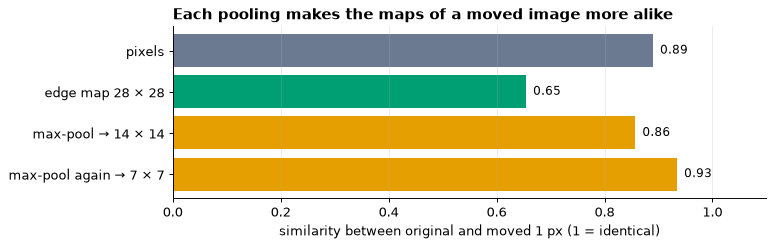

In [34]:
def similarity(a, b):
    return F.cosine_similarity(a.flatten(1), b.flatten(1)).mean().item()

x0 = X_val[:2000]; x1 = shift_images(x0, dx=1)
sobel = torch.tensor(KERNELS["vertical edges"])[None, None]
stages = {"pixels": lambda x: x,
          "edge map 28 × 28": lambda x: F.conv2d(x, sobel, padding=1).abs(),
          "max-pool → 14 × 14": lambda x: F.max_pool2d(F.conv2d(x, sobel, padding=1).abs(), 2),
          "max-pool again → 7 × 7": lambda x: F.max_pool2d(F.conv2d(x, sobel, padding=1).abs(), 4)}
sims = {name: similarity(f(x0), f(x1)) for name, f in stages.items()}
fig, ax = plt.subplots(figsize=(9, 2.8), layout="constrained")
ax.barh(range(4), list(sims.values()), color=[PALETTE["grey"], PALETTE["green"], PALETTE["orange"], PALETTE["orange"]])
ax.set_yticks(range(4), list(sims)); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
label_bars(ax, list(sims.values()), decimals=2); ax.set_xlim(0, 1.1)
ax.set(xlabel="similarity between original and moved 1 px (1 = identical)",
       title="Each pooling makes the maps of a moved image more alike")
plt.show()

<a id="sec-12"></a>
# 12. 🧱 Stack layers

> 🎞️ **Slides:** [Stack layers: edges → shapes → parts → objects](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-layers)

The full recipe repeats **conv → ReLU → pool** a few times: the maps get **smaller** but **more numerous**. At the end, the small maps are flattened into one list and a dense layer (the MLP you know) makes the decision.

```
1×28×28 ─conv 16─► 16×28×28 ─pool─► 16×14×14 ─conv 32─► 32×14×14 ─pool─► 32×7×7 ─flatten─► 1568 ─linear─► 10
```

Each layer combines the patterns of the layer before: edges → shapes → parts → objects. Nobody programs "heel" or "collar": the network discovers what it needs from labelled examples. Let's build it and follow one image through it (untrained for now: we only look at the **shapes**).

In [35]:
class FashionCNN(nn.Module):
    def __init__(self, c1=16, c2=32):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, c1, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # c1 learned kernels, 28 -> 14
            nn.Conv2d(c1, c2, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # c2 kernels over c1 maps, 14 -> 7
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(c2 * 7 * 7, 10))

    def forward(self, x):
        return self.head(self.features(x))

set_seed(SEED)
cnn = FashionCNN().eval()
x = X_train[i:i + 1]
trace = [{"layer": "input image", "output shape": tuple(x.shape[1:]), "numbers": x[0].numel(), "weights": 0}]
with torch.no_grad():
    for layer in [*cnn.features, *cnn.head]:
        x = layer(x)
        trace.append({"layer": repr(layer).split("(")[0] + ("" if not isinstance(layer, nn.Conv2d) else
                      f" ({layer.out_channels} kernels of {layer.in_channels} × 3 × 3)"),
                      "output shape": tuple(x.shape[1:]), "numbers": x[0].numel(), "weights": count_parameters(layer)})
trace = pd.DataFrame(trace)
display(trace.style.format({"numbers": "{:,}", "weights": "{:,}"}))
print(f"total weights: {trace['weights'].sum():,}")

,layer,output shape,numbers,weights
0,input image,"(1, 28, 28)",784,0
1,Conv2d (16 kernels of 1 × 3 × 3),"(16, 28, 28)","12,544",160
2,ReLU,"(16, 28, 28)","12,544",0
3,MaxPool2d,"(16, 14, 14)","3,136",0
4,Conv2d (32 kernels of 16 × 3 × 3),"(32, 14, 14)","6,272","4,640"
5,ReLU,"(32, 14, 14)","6,272",0
6,MaxPool2d,"(32, 7, 7)","1,568",0
7,Flatten,"(1568,)","1,568",0
8,Dropout,"(1568,)","1,568",0
9,Linear,"(10,)",10,"15,690"


total weights: 20,490


<a id="sec-13"></a>
# 13. ⚖️ MLP vs CNN: what changes

> 🎞️ **Slides:** [MLP vs CNN: what changes](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-vs)

An MLP neuron sees **every pixel**, with its own weight for each. A CNN output sees a **3 × 3 patch**, and the same 9 weights slide everywhere. The numbers below are pure architecture, no training needed:

In [36]:
pd.DataFrame({"MLP (one neuron)": [f"{28 * 28:,} + 1 = {28 * 28 + 1:,}", f"{224 * 224 * 3:,} + 1 = {224 * 224 * 3 + 1:,}"],
              "CNN (one 3 × 3 kernel)": ["3 × 3 + 1 = 10", "3 × 3 × 3 + 1 = 28"]},
             index=["weights for one detector, 28 × 28 grey", "… on a 224 × 224 colour photo"])

,MLP (one neuron),CNN (one 3 × 3 kernel)
"weights for one detector, 28 × 28 grey",784 + 1 = 785,3 × 3 + 1 = 10
… on a 224 × 224 colour photo,"150,528 + 1 = 150,529",3 × 3 × 3 + 1 = 28


### 🧪 Move the image: what happens inside?

Move a trouser 3 pixels to the right. A kernel's feature map **moves with it**, exactly the same pattern, just shifted. The MLP's first-layer neurons instead give **different answers**, because each one is glued to fixed pixel positions.

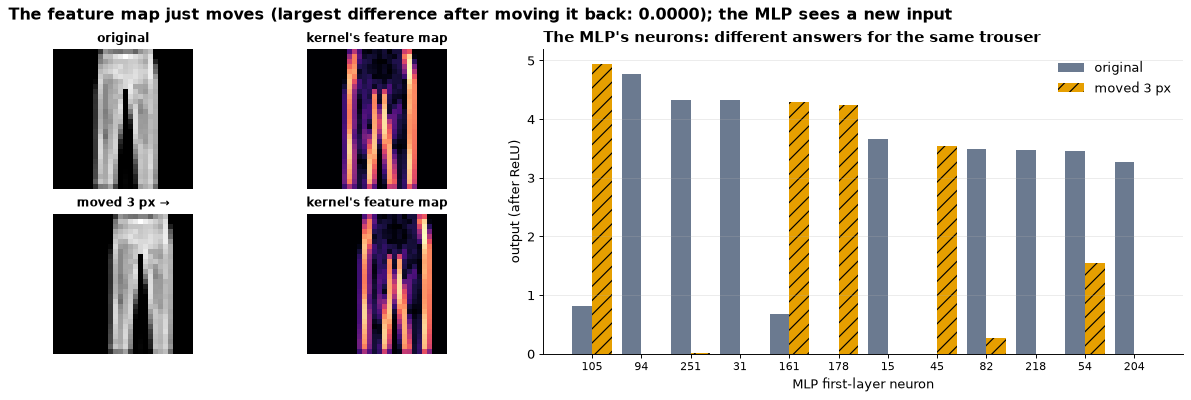

MLP first-layer neurons whose output changed by more than half: 90 of 256


In [37]:
j = first[1]                                                     # the first trouser
x0 = X_train[j:j + 1]; x3 = shift_images(x0, dx=3)
m0, m3 = apply_kernel(x0[0, 0].numpy(), KERNELS["vertical edges"]), apply_kernel(x3[0, 0].numpy(), KERNELS["vertical edges"])
gap = np.abs(shift_images(torch.tensor(m0), dx=3).numpy() - m3).max()
with torch.no_grad():
    h0 = torch.relu(mlp[1](x0.flatten(1)))[0].numpy(); h3 = torch.relu(mlp[1](x3.flatten(1)))[0].numpy()
show = np.argsort(-np.maximum(h0, h3))[:12]          # 12 neurons that react most to this trouser

fig = plt.figure(figsize=(14, 4.6), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 2.6])
for row, (xx, mm, name) in enumerate(((x0, m0, "original"), (x3, m3, "moved 3 px →"))):
    a = fig.add_subplot(gs[row, 0]); a.imshow(xx[0, 0], cmap="gray"); a.axis("off"); a.set_title(name, loc="center", fontsize=10)
    b = fig.add_subplot(gs[row, 1]); b.imshow(np.abs(mm), cmap="magma"); b.axis("off")
    b.set_title("kernel's feature map", loc="center", fontsize=10)
ax = fig.add_subplot(gs[:, 2])
pos = np.arange(len(show))
ax.bar(pos - 0.2, h0[show], 0.4, color=PALETTE["grey"], label="original")
ax.bar(pos + 0.2, h3[show], 0.4, color=PALETTE["orange"], label="moved 3 px", hatch="//")
ax.set_xticks(pos, [str(k) for k in show], fontsize=9); ax.set(xlabel="MLP first-layer neuron", ylabel="output (after ReLU)",
                                                         title="The MLP's neurons: different answers for the same trouser")
ax.legend(); ax.grid(axis="x", visible=False)
fig.suptitle(f"The feature map just moves (largest difference after moving it back: {gap:.4f}); the MLP sees a new input",
             x=0.01, ha="left", fontweight="bold")
plt.show()
changed = np.abs(h3 - h0) > 0.5 * np.maximum(np.abs(h0), 1e-3)
print(f"MLP first-layer neurons whose output changed by more than half: {changed.sum()} of 256")

<a id="sec-14"></a>
# 14. 🧑‍💻 The code: train a small CNN and look inside

> 🎞️ **Slides:** [A small CNN in PyTorch](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-code) · [Stack layers (what the maps react to)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-layers)

Same optimiser (AdamW), same loss, same epochs as the MLP, same training function: only the architecture changes. The kernels start random and are **learned**.

In [38]:
EPOCHS_CNN = 10 if RUN_HEAVY else EPOCHS
set_seed(SEED)
cnn = FashionCNN()
print(f"CNN parameters: {count_parameters(cnn):,}  vs  MLP: {count_parameters(mlp):,}")
hist_cnn = train_model(cnn, train_dl, val_dl, epochs=EPOCHS_CNN, lr=2e-3)
res_cnn = evaluate(cnn, val_dl)
shift_cnn = shift_curve(cnn)
acc_cnn_shift = shift_cnn[SHIFTS.index(3)]
torch.save(cnn.state_dict(), models_dir() / "fashion_cnn.pt")
print(f"CNN validation accuracy: {res_cnn['accuracy']:.1%} | with images moved 3 px: {acc_cnn_shift:.1%}")

CNN parameters: 20,490  vs  MLP: 235,146


epoch  1/4: train loss 0.570 acc 0.796 | val loss 0.398 acc 0.854 | 4.8 s


epoch  2/4: train loss 0.373 acc 0.867 | val loss 0.341 acc 0.880 | 5.2 s


epoch  3/4: train loss 0.335 acc 0.880 | val loss 0.311 acc 0.890 | 4.5 s


epoch  4/4: train loss 0.309 acc 0.889 | val loss 0.292 acc 0.897 | 5.8 s


CNN validation accuracy: 89.7% | with images moved 3 px: 50.3%


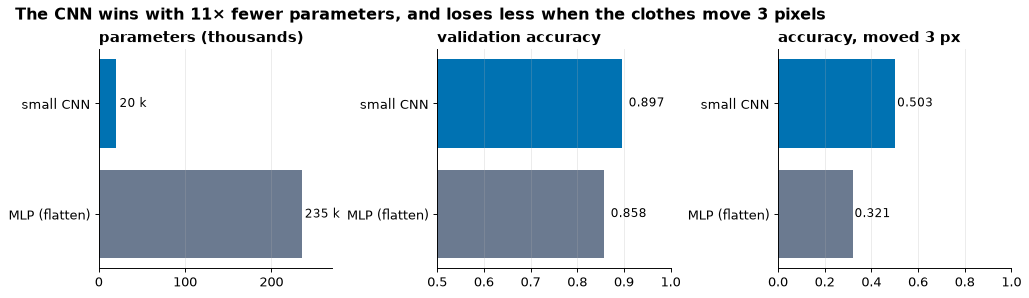

,parameters,validation accuracy,"accuracy, moved 3 px",training time (s)
MLP (flatten),"235,146",85.8%,32.0%,6
small CNN,"20,490",89.7%,50.3%,20


In [39]:
board = pd.DataFrame({
    "parameters": [count_parameters(mlp), count_parameters(cnn)],
    "validation accuracy": [res_mlp["accuracy"], res_cnn["accuracy"]],
    "accuracy, moved 3 px": [acc_mlp_shift, acc_cnn_shift],
    "training time (s)": [sum(hist_mlp["seconds"]), sum(hist_cnn["seconds"])],
}, index=["MLP (flatten)", "small CNN"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
colours = [PALETTE["grey"], PALETTE["blue"]]
for ax, col in zip(axes, ("parameters", "validation accuracy", "accuracy, moved 3 px")):
    vals = board[col].values / (1000 if col == "parameters" else 1)
    ax.barh(range(2), vals, color=colours); ax.set_yticks(range(2), board.index)
    label_bars(ax, vals, decimals=0 if col == "parameters" else 3, suffix=" k" if col == "parameters" else "")
    ax.set_title(col if col != "parameters" else "parameters (thousands)", loc="left"); ax.grid(axis="y", visible=False)
axes[1].set_xlim(0.5, 1.0); axes[2].set_xlim(0, 1.0)
fig.suptitle(f"The CNN wins with {count_parameters(mlp) / count_parameters(cnn):.0f}× fewer parameters, "
             "and loses less when the clothes move 3 pixels", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-mlp-vs-cnn.png")
plt.show()
display(board.style.format({"parameters": "{:,}", "validation accuracy": "{:.1%}", "accuracy, moved 3 px": "{:.1%}",
                            "training time (s)": "{:.0f}"}))

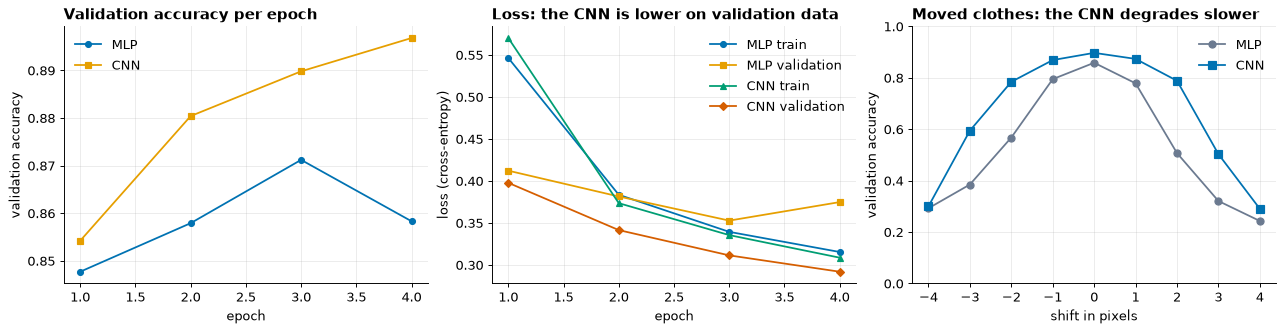

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained")
plot_history({"MLP": hist_mlp["acc_va"], "CNN": hist_cnn["acc_va"]}, ylabel="validation accuracy",
             title="Validation accuracy per epoch", ax=axes[0])
plot_history({"MLP train": hist_mlp["loss_tr"], "MLP validation": hist_mlp["loss_va"],
              "CNN train": hist_cnn["loss_tr"], "CNN validation": hist_cnn["loss_va"]},
             ylabel="loss (cross-entropy)", title="Loss: the CNN is lower on validation data", ax=axes[1])
axes[2].plot(SHIFTS, shift_mlp, marker="o", color=PALETTE["grey"], label="MLP")
axes[2].plot(SHIFTS, shift_cnn, marker="s", color=PALETTE["blue"], label="CNN")
axes[2].set(xlabel="shift in pixels", ylabel="validation accuracy", ylim=(0, 1), title="Moved clothes: the CNN degrades slower")
axes[2].legend()
plt.show()

The CNN is more accurate with about a tenth of the parameters. On moved images it also drops, but **more slowly** than the MLP: its kernels find edges anywhere, and pooling forgives small shifts. It is *more tolerant, not immune*: the last layer still reads the 7 × 7 maps at fixed positions. The full fix is to show the model moved images during training (**data augmentation**, exercise 5 and notebook 04).

## 🔬 Inside the CNN: learned kernels and feature maps

Which kernels did the first layer learn? And what does our ankle boot look like after each layer? `capture_activations` uses **forward hooks** (small functions PyTorch calls when a layer runs) to grab the feature maps.

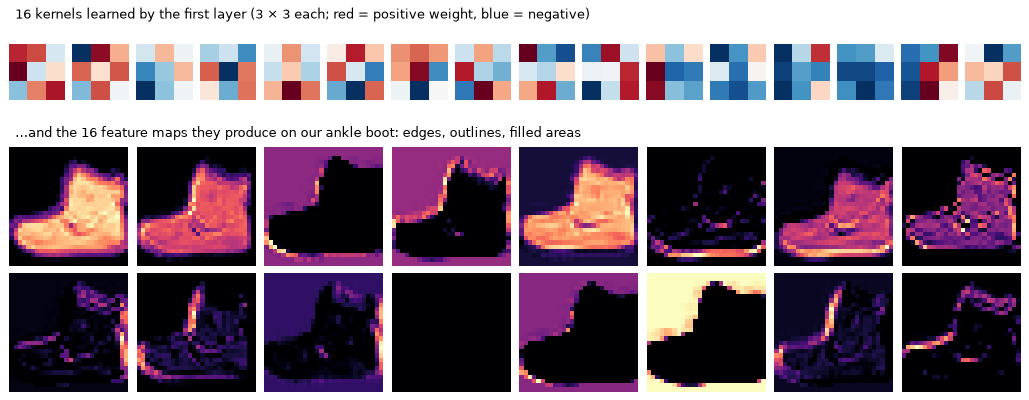

In [41]:
LAYERS = {"conv 1 + ReLU": cnn.features[1], "pool 1": cnn.features[2], "conv 2 + ReLU": cnn.features[4], "pool 2": cnn.features[5]}
maps = capture_activations(cnn, X_train[i:i + 1], LAYERS)

kernels = cnn.features[0].weight.detach()[:, 0].numpy()       # (16, 3, 3)
fig = plt.figure(figsize=(12, 4.6), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[0.42, 1])
ax_k = top.subplots(1, 16)
for ax, k in zip(ax_k, kernels):
    lim = np.abs(k).max(); ax.imshow(k, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
top.suptitle("16 kernels learned by the first layer (3 × 3 each; red = positive weight, blue = negative)", x=0.01, ha="left", fontsize=11)
ax_m = bottom.subplots(2, 8)
for ax, fm in zip(ax_m.ravel(), maps["conv 1 + ReLU"][0].numpy()):
    ax.imshow(fm, cmap="magma"); ax.axis("off")
bottom.suptitle("…and the 16 feature maps they produce on our ankle boot: edges, outlines, filled areas", x=0.01, ha="left", fontsize=11)
save_slide(fig, "cv-feature-maps.png")
plt.show()

Some kernels look like our hand-made edge detectors (negative on one side, positive on the other), others react to the whole filled shape or to the background. Nobody told the network to look for edges: **it learned that edges are useful** to tell clothes apart.

Now follow the boot **through all the layers** (the 8 most active maps of each stage): the maps get smaller and more abstract, from "edges at this pixel" to "this kind of part, roughly here".

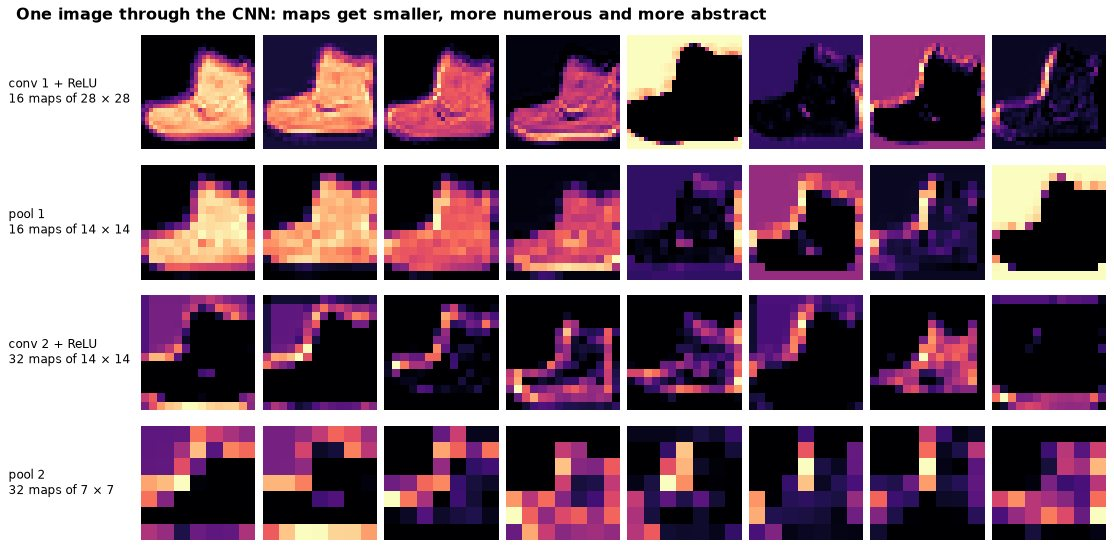

In [42]:
def layer_tour(index, n=8, title=None):
    acts = capture_activations(cnn, X_val[index:index + 1] if index >= 0 else X_train[i:i + 1], LAYERS)
    fig, axes = plt.subplots(len(acts), n + 1, figsize=(13, 6.4), layout="constrained")
    for row, (name, a) in enumerate(acts.items()):
        a = a[0].numpy()
        top_maps = np.argsort(-a.reshape(len(a), -1).mean(1))[:n]
        axes[row, 0].text(0.0, 0.5, f"{name}\n{a.shape[0]} maps of {a.shape[1]} × {a.shape[2]}", va="center", fontsize=10)
        for col, m in enumerate(top_maps, start=1):
            axes[row, col].imshow(a[m], cmap="magma")
    no_axes(axes)
    fig.suptitle(title or "One image through the CNN: maps get smaller, more numerous and more abstract",
                 x=0.01, ha="left", fontweight="bold")
    show_jpeg(fig, quality=84)

layer_tour(-1)

### 🧩 What does a layer-2 unit react to?

A layer-2 unit sees an 8 × 8 patch of the image (its 3 × 3 window over pooled maps of 3 × 3 windows). For 4 picky units that prefer different classes, we search the 10,000 validation images for the 5 places that excite each unit most, and draw the 8 × 8 patch it was looking at. This is the "edges → shapes → parts" idea of the slides, measured on our own model.

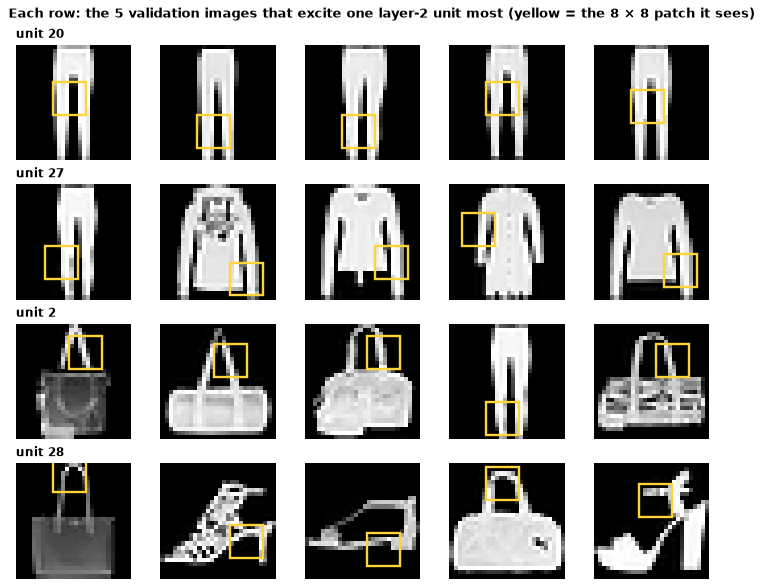

In [43]:
with torch.no_grad():
    act2 = torch.cat([capture_activations(cnn, xb, {"c2": cnn.features[4]})["c2"] for xb in X_val.split(2000)])  # (N, 32, 14, 14)
peak, where = act2.flatten(2).max(2)                                   # strongest response of each unit in each image
order = np.argsort(-peak.std(0).numpy()).tolist()                      # pickiest units first (highest variation)
units, seen_cls = [], set()
for u in order:
    dom = int(pd.Series(y_val[torch.argsort(peak[:, u], descending=True)[:5]].numpy()).mode()[0])
    if dom not in seen_cls:
        units.append(u); seen_cls.add(dom)
    if len(units) == 4:
        break
units += [u for u in order if u not in units][:4 - len(units)]

fig, axes = plt.subplots(len(units), 5, figsize=(8.5, 6.8), layout="constrained")
for row, u in enumerate(units):
    best = torch.argsort(peak[:, u], descending=True)[:5]
    for col, n in enumerate(best.tolist()):
        rr, cc = divmod(where[n, u].item(), 14)
        ax = axes[row, col]; ax.imshow(X_val_u8[n], cmap="gray")
        ax.add_patch(Rectangle((2 * cc - 3.5, 2 * rr - 3.5), 8, 8, fill=False, ec=YELLOW, lw=2))
        ax.set_xlim(-.5, 27.5); ax.set_ylim(27.5, -.5)
    axes[row, 0].set_title(f"unit {u}", loc="left", fontsize=10)
no_axes(axes)
fig.suptitle("Each row: the 5 validation images that excite one layer-2 unit most (yellow = the 8 × 8 patch it sees)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.show()

#### 🎛️ Try it: pick a validation image

Move the slider to send another validation image through the CNN. Compare a bag, a sandal and a shirt: different maps light up.

In [44]:
try:
    import ipywidgets as widgets

    def tour(index=0):
        p = res_cnn["proba"][index]
        layer_tour(index, title=f"validation image {index}: true {FASHION_CLASSES[y_val[index]]}, "
                                f"CNN says {FASHION_CLASSES[p.argmax()]} ({p.max():.0%})")

    widgets.interact(tour, index=widgets.IntSlider(0, 0, len(X_val) - 1, continuous_update=False))
except ImportError:
    print("ipywidgets is not installed: call layer_tour(index) by hand.")

interactive(children=(IntSlider(value=0, continuous_update=False, description='index', max=9999), Output()), _…

### 💬 Discussion: why fewer parameters but better?

The CNN has about 10× fewer parameters than the MLP and is more accurate. How can a *smaller* model be *better*?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Two built-in assumptions ("inductive biases") that are true for images: **(1) locality**: a pixel is mostly related to its neighbours, so a kernel only looks at 3 × 3 pixels instead of all 784; **(2) weight sharing**: the same pattern can appear anywhere, so the same 9 weights are reused at every position. The MLP has to learn a separate weight for "edge at position 100" and "edge at position 101". Fewer parameters also means less room to memorise noise (less overfitting). The shift curve and the shuffled-pixels experiment show both points directly: the MLP did not care about pixel order (no locality), and the CNN degrades more slowly when things move (sharing + pooling).
</details>

<a id="sec-15"></a>
# 15. 🏆 The evidence: ImageNet, and our own final exam

> 🎞️ **Slides:** [ImageNet: the year CNNs took over](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-imagenet) · [Notebook 03: now, in practice](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#cv1-nb03)

**ImageNet** (ILSVRC): 1.2 million training photos, 1,000 classes. *Top-5 error* = the right class is not among the model's 5 best guesses. In 2012 a CNN (AlexNet) cut the error from 25.8% to 16.4% in one year; every winner after it is a CNN. The numbers below are the published winning results (Russakovsky et al., 2015; He et al., 2016).

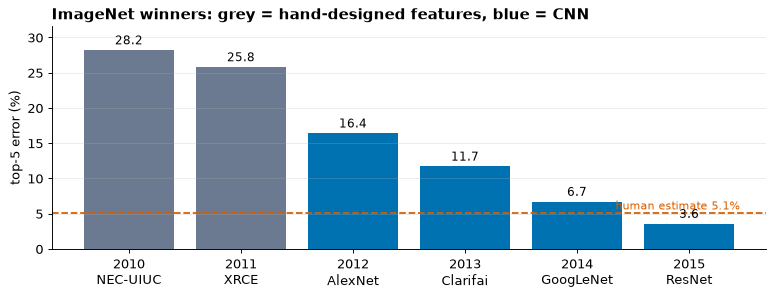

In [45]:
ilsvrc = pd.DataFrame({"year": [2010, 2011, 2012, 2013, 2014, 2015],
                       "winner": ["NEC-UIUC", "XRCE", "AlexNet", "Clarifai", "GoogLeNet", "ResNet"],
                       "top-5 error (%)": [28.2, 25.8, 16.4, 11.7, 6.7, 3.57],
                       "CNN": [False, False, True, True, True, True]})
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.bar([f"{y}\n{w}" for y, w in zip(ilsvrc["year"], ilsvrc["winner"])], ilsvrc["top-5 error (%)"],
       color=[PALETTE["blue"] if c else PALETTE["grey"] for c in ilsvrc["CNN"]])
label_bars(ax, ilsvrc["top-5 error (%)"], decimals=1, horizontal=False)
ax.axhline(5.1, color=PALETTE["red"], ls="--", lw=1.5); ax.text(5.45, 5.6, "human estimate 5.1%", color=PALETTE["red"], ha="right", fontsize=9)
ax.set(ylabel="top-5 error (%)", title="ImageNet winners: grey = hand-designed features, blue = CNN")
ax.grid(axis="x", visible=False)
plt.show()

### 🔓 Our final exam: the test set, once

Validation chose the CNN. Now, **once**, we open the locked **test** set: 10,000 images that played no part in training or in choosing the model. This is the number you would report.

In [46]:
test_mlp = evaluate(mlp, test_dl)
test_cnn = evaluate(cnn, test_dl)
pd.DataFrame({"validation accuracy": [res_mlp["accuracy"], res_cnn["accuracy"]],
              "test accuracy (final)": [test_mlp["accuracy"], test_cnn["accuracy"]]},
             index=["MLP (flatten)", "small CNN"]).style.format("{:.1%}")

,validation accuracy,test accuracy (final)
MLP (flatten),85.8%,85.7%
small CNN,89.7%,88.8%


The test scores are usually a little different from the validation ones (often slightly lower): we picked the model that looked best on validation, so validation is slightly optimistic. The gap is small, so validation was an honest stand-in, and the **test** number is the one to report.

### 🧮 The confusion matrix, by families

We reorder the classes into two families, **clothes** (tops, dress, trouser) and **shoes & bags**, and draw a box around each family. Almost every mistake stays **inside** a family.

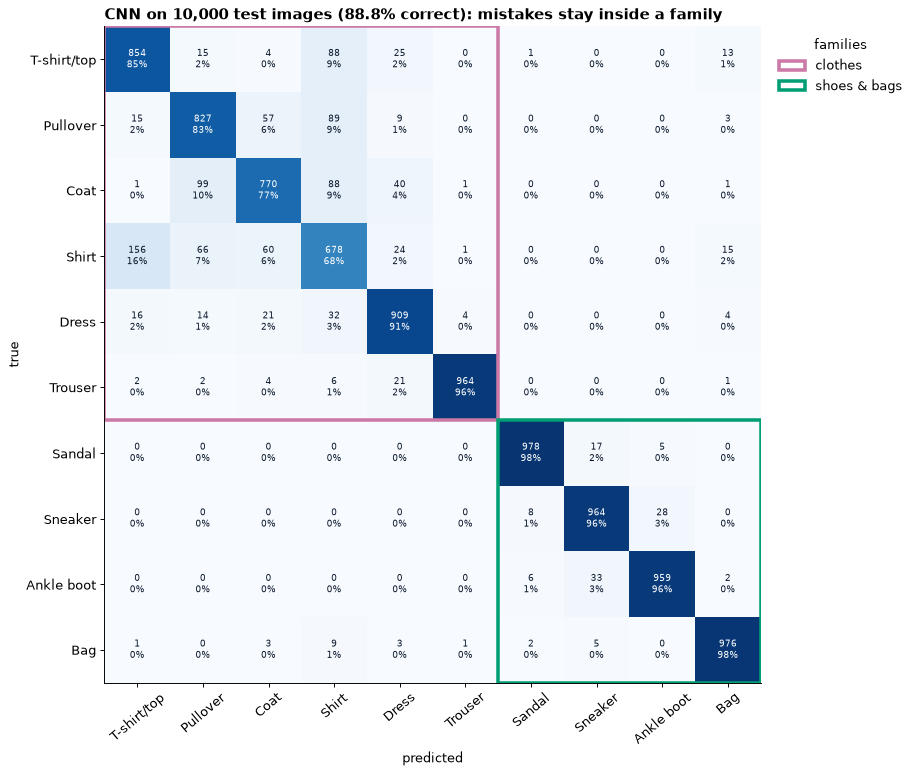

recall per class (worst first):
Shirt          0.678
Coat           0.770
Pullover       0.827
T-shirt/top    0.854
Dress          0.909
Ankle boot     0.959
Sneaker        0.964
Trouser        0.964
Bag            0.976
Sandal         0.978


In [47]:
CLOTHES, SHOES_BAGS = [0, 2, 4, 6, 3, 1], [5, 7, 9, 8]
order = CLOTHES + SHOES_BAGS
cm = test_cnn["confusion"][np.ix_(order, order)]
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
plot_confusion(cm, [FASHION_CLASSES[c] for c in order], ax=ax,
               title=f"CNN on 10,000 test images ({test_cnn['accuracy']:.1%} correct): mistakes stay inside a family")
for t in ax.texts:
    t.set_fontsize(8)
boxes = []
for start, size, colour, name in ((0, 6, PALETTE["purple"], "clothes"), (6, 4, PALETTE["green"], "shoes & bags")):
    boxes.append(ax.add_patch(Rectangle((start - .5, start - .5), size, size, fill=False, ec=colour, lw=3, label=name)))
ax.legend(handles=boxes, loc="upper left", bbox_to_anchor=(1.01, 1), title="families")
ax.tick_params(axis="x", rotation=40)
plt.show()
per_class = pd.Series(test_cnn["confusion"].diagonal() / test_cnn["confusion"].sum(1), index=FASHION_CLASSES)
print("recall per class (worst first):"); print(per_class.sort_values().round(3).to_string())

**Two families instead of ten.** If the shop only needed "clothes" vs "shoes & bags", could we reuse the 10-class model? Yes: map each prediction to its family and add up the four blocks of the matrix above.

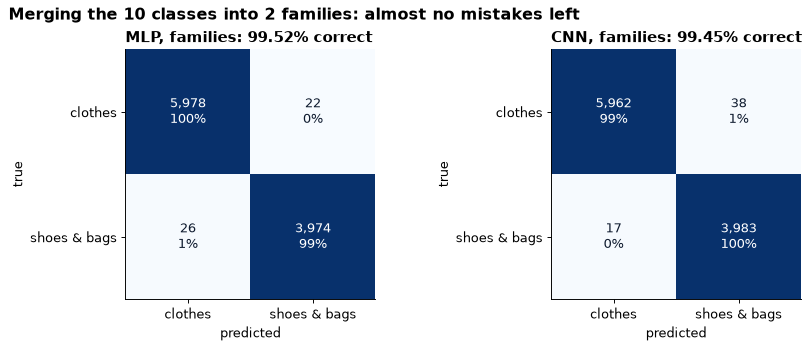

In [48]:
family = np.isin(np.arange(10), SHOES_BAGS).astype(int)          # 0 = clothes, 1 = shoes & bags
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, res) in zip(axes, (("MLP", test_mlp), ("CNN", test_cnn))):
    t, p = family[res["y_true"]], family[res["y_pred"]]
    cm2 = np.zeros((2, 2), dtype=int); np.add.at(cm2, (t, p), 1)
    plot_confusion(cm2, ["clothes", "shoes & bags"], ax=ax, title=f"{name}, families: {(t == p).mean():.2%} correct")
fig.suptitle("Merging the 10 classes into 2 families: almost no mistakes left", x=0.01, ha="left", fontweight="bold")
plt.show()

### 🔀 The most confused pairs, with examples

Which (true → predicted) pairs have the most mistakes? For each, 6 test images the CNN got wrong that way.

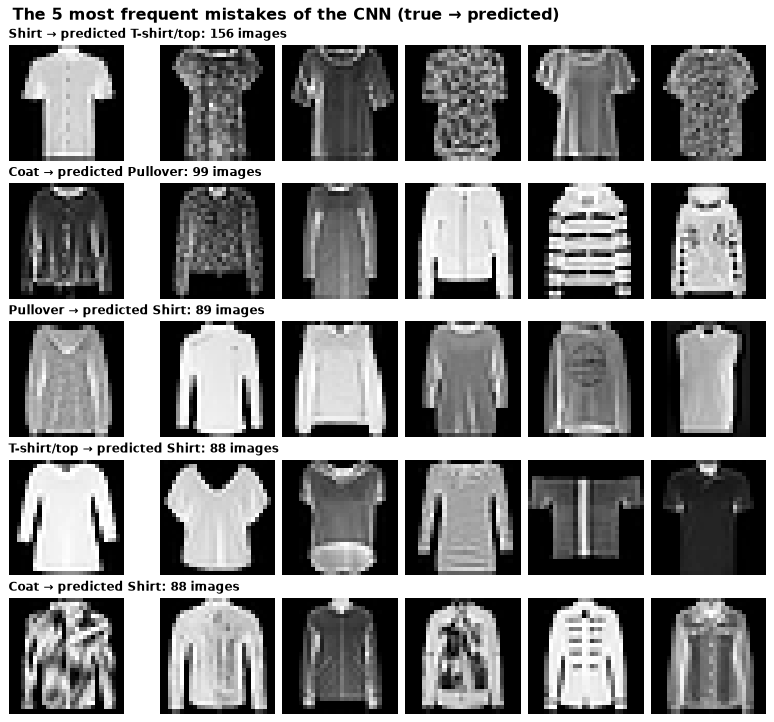

In [49]:
off = test_cnn["confusion"].copy(); np.fill_diagonal(off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
fig, axes = plt.subplots(len(pairs), 6, figsize=(9, 8.4), layout="constrained")
for row, (t, p) in enumerate(pairs):
    sel = np.flatnonzero((test_cnn["y_true"] == t) & (test_cnn["y_pred"] == p))[:6]
    for col, k in enumerate(sel):
        axes[row, col].imshow(X_test_u8[k], cmap="gray")
    axes[row, 0].set_title(f"{FASHION_CLASSES[t]} → predicted {FASHION_CLASSES[p]}: {off[t, p]} images",
                           loc="left", fontsize=10)
no_axes(axes)
fig.suptitle("The 5 most frequent mistakes of the CNN (true → predicted)", x=0.01, ha="left", fontweight="bold")
plt.show()

### 🖼️ The most confident mistakes

Looking at **the errors the model was most sure about** tells you *why* it fails: a confusing label, a weird photo, or two classes that really overlap.

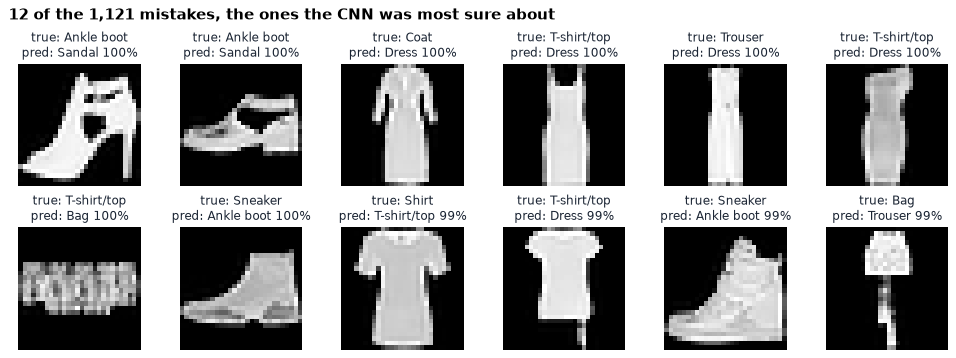

In [50]:
proba = test_cnn["proba"]                                     # (10000, 10), rows in the test-set order
wrong = np.flatnonzero(test_cnn["y_pred"] != test_cnn["y_true"])
worst = wrong[np.argsort(-proba[wrong].max(1))][:12]
titles = [f"true: {FASHION_CLASSES[test_cnn['y_true'][k]]}\npred: {FASHION_CLASSES[test_cnn['y_pred'][k]]} "
          f"{proba[k].max():.0%}" for k in worst]
fig = show_grid([X_test_u8[k] for k in worst], titles, ncols=6, size=1.9,
                suptitle=f"12 of the {len(wrong):,} mistakes, the ones the CNN was most sure about")
plt.show()

Many of these are debatable even for a human: a "shirt" that looks like a T-shirt, a "bag" photographed like a top, a sandal that could be a sneaker. At 28 × 28 pixels and grey only, some information is simply gone. Better models help, but **the data sets the ceiling**.

### 💬 Discussion: is 90% good?

The CNN gets about 9 out of 10 test images right, and almost 100% of the families. Would you deploy it to tag the products of an online shop automatically? What would you do with the cases it is unsure about?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Depends on the cost of an error. A wrong "shirt vs T-shirt" tag is cheap; a wrong "sandal vs ankle boot" might annoy customers. The family view shows the model almost never confuses a shoe with a top: the hard part is *within* tops. A common design: auto-tag when the top probability is above a threshold (e.g. 95%) and send the rest to a person (the threshold idea from Lesson 02). Also: real shop photos are colour, larger and varied; Fashion-MNIST is a clean benchmark. Notebook 04 moves to real photos.
</details>

<a id="sec-16"></a>
# 16. 🔬 Where does the model look, and what did it learn?

## 🧠 How it works: saliency maps

**Simple idea.** Ask the model: "if I made *this* pixel a little brighter, how much would the score of class *k* change?" The answer for every pixel is a **saliency map** (computed with the same gradients used for training, but with respect to the **input pixels** instead of the weights).

**Reading it.** Red = a brighter pixel here would **raise** the score of that class; blue = it would **lower** it; white = this pixel does not matter. Notebook 04 uses a smoother cousin, **Grad-CAM**, on real photos.

**Limits.** Single-image gradients are speckled, so below we average 25 slightly noisy copies of each image (**SmoothGrad**). Even then, it is a local clue ("what would change the answer right now"), not a full explanation.

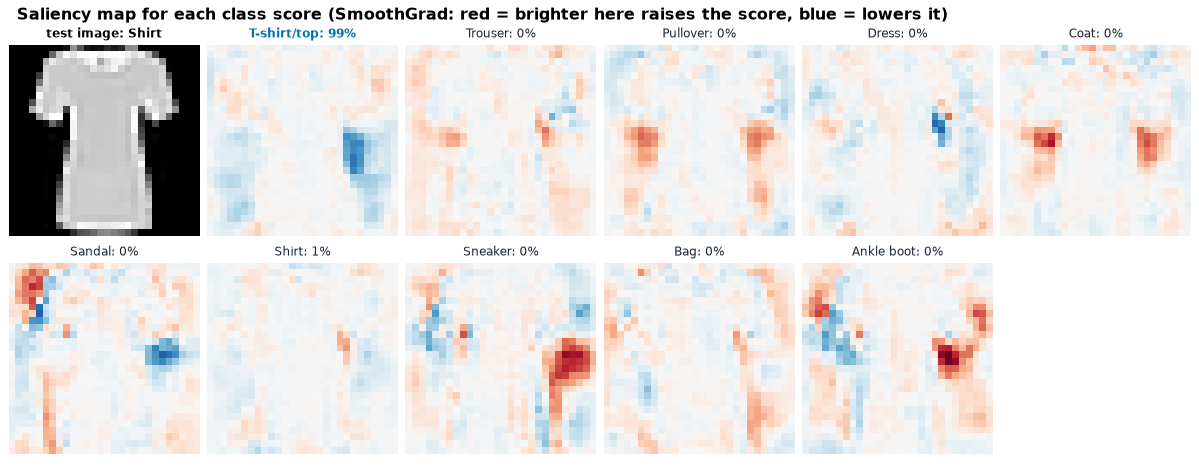

In [51]:
# A shirt that the CNN wrongly calls something else: what pushes each class score up or down?
set_seed(SEED)
shirt_errors = np.flatnonzero((test_cnn["y_true"] == 6) & (test_cnn["y_pred"] != 6))
k = int(shirt_errors[np.argmax(proba[shirt_errors].max(1))])
grads = np.stack([input_gradients(cnn, X_test[k:k + 1], c, samples=25, noise=0.15)[0] for c in range(10)])  # (10, 28, 28)
lim = np.abs(grads).max()
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4), layout="constrained")
axes[0, 0].imshow(X_test_u8[k], cmap="gray")
axes[0, 0].set_title(f"test image: {FASHION_CLASSES[test_cnn['y_true'][k]]}", loc="center", fontsize=10)
for c, ax in zip(range(10), axes.ravel()[1:]):
    ax.imshow(grads[c], cmap="RdBu_r", vmin=-lim, vmax=lim)
    best = c == proba[k].argmax()
    ax.set_title(f"{FASHION_CLASSES[c]}: {proba[k, c]:.0%}", loc="center", fontsize=10,
                 color=PALETTE["blue"] if best else "#1a2433", fontweight="bold" if best else "normal")
no_axes(axes)
fig.suptitle("Saliency map for each class score (SmoothGrad: red = brighter here raises the score, blue = lowers it)",
             x=0.01, ha="left", fontweight="bold")
plt.show()

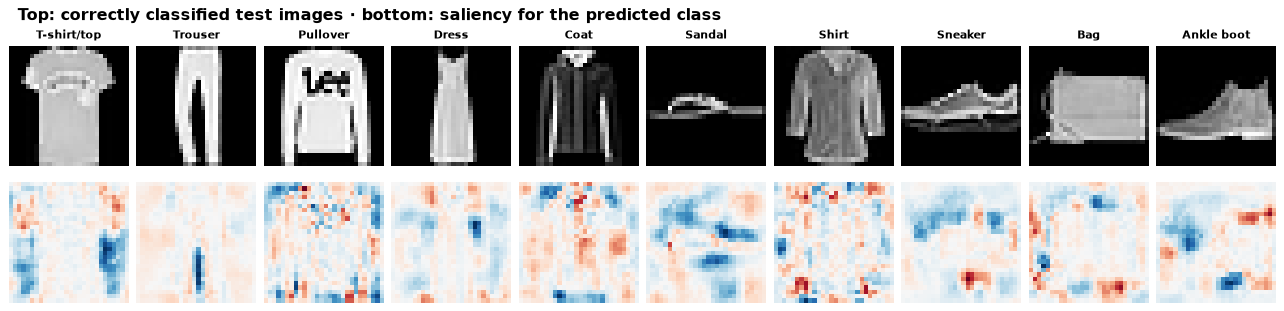

In [52]:
# Where does the CNN look for the class it predicts? One correct test image per class.
set_seed(SEED)
picks = [int(np.flatnonzero((test_cnn["y_true"] == c) & (test_cnn["y_pred"] == c))[0]) for c in range(10)]
sal = [input_gradients(cnn, X_test[k:k + 1], c, samples=25, noise=0.15)[0] for k, c in zip(picks, range(10))]
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6), layout="constrained")
for col, (k, s) in enumerate(zip(picks, sal)):
    axes[0, col].imshow(X_test_u8[k], cmap="gray"); axes[0, col].set_title(FASHION_CLASSES[col], loc="center", fontsize=9)
    lim_s = np.abs(s).max(); axes[1, col].imshow(s, cmap="RdBu_r", vmin=-lim_s, vmax=lim_s)
no_axes(axes)
fig.suptitle("Top: correctly classified test images · bottom: saliency for the predicted class",
             x=0.01, ha="left", fontweight="bold")
plt.show()

Look for the useful evidence: the gap between the trouser legs, the strap of a bag, the heel and the sole of the shoes, the collar and sleeves of tops.

### 🗺️ A map of what the CNN learned

The last convolution block turns each image into **1,568 numbers** (32 maps of 7 × 7). Images the CNN finds similar get similar numbers. **t-SNE** squeezes those 1,568 numbers to 2 so we can draw one dot per image: nearby dots = images the model considers alike. On the left, the same map computed from the **raw pixels** for comparison.

t-SNE on 2,000 validation images: 4 s
  raw pixels (784 numbers): nearest neighbour has the same class 76.0% of the time
  CNN features (1,568 numbers): nearest neighbour has the same class 80.6% of the time


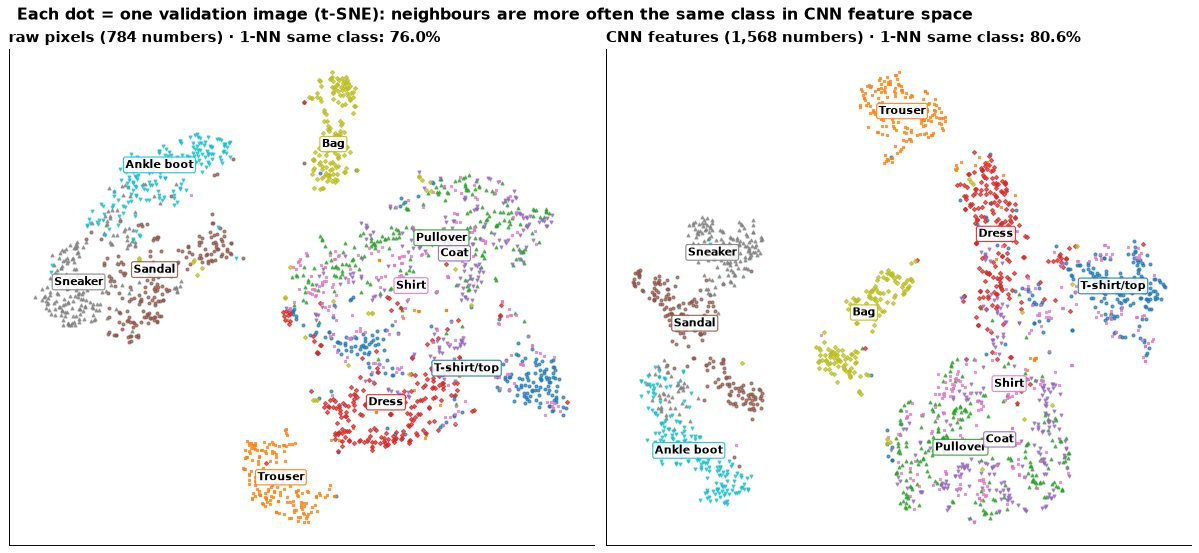

In [53]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

n_map = 5000 if RUN_HEAVY else 2000
xs, ys = X_val[:n_map], y_val[:n_map].numpy()
with torch.no_grad():
    learned = cnn.features(xs).flatten(1).numpy()                     # (n, 1568): what the CNN computed
spaces = {"raw pixels (784 numbers)": xs.flatten(1).numpy(), "CNN features (1,568 numbers)": learned}
t0 = time.perf_counter()
nn_same = {}
for name, v in spaces.items():
    nbr = NearestNeighbors(n_neighbors=2).fit(v).kneighbors(v, return_distance=False)[:, 1]
    nn_same[name] = float((ys[nbr] == ys).mean())                     # how often the closest image is the same class
points = {name: TSNE(2, init="pca", perplexity=30, random_state=SEED).fit_transform(PCA(50, random_state=SEED).fit_transform(v))
          for name, v in spaces.items()}
print(f"t-SNE on {n_map:,} validation images: {time.perf_counter() - t0:.0f} s")
for name, score in nn_same.items():
    print(f"  {name}: nearest neighbour has the same class {score:.1%} of the time")

palette = mpl.colormaps["tab10"].colors
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), layout="constrained")
for ax, (name, pts) in zip(axes, points.items()):
    for c in range(10):
        m = ys == c
        ax.scatter(pts[m, 0], pts[m, 1], s=6, color=palette[c], alpha=.7, marker=["o", "s", "^", "D", "v"][c % 5])
        cx, cy = np.median(pts[m], axis=0)
        ax.text(cx, cy, FASHION_CLASSES[c], fontsize=9.5, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.18", fc="white", ec=palette[c], alpha=.88))
    ax.set_title(f"{name} · 1-NN same class: {nn_same[name]:.1%}", loc="left")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Each dot = one validation image (t-SNE): neighbours are more often the same class in CNN feature space",
             x=0.01, ha="left", fontweight="bold")
show_jpeg(fig, quality=84)

Because t-SNE can stretch or shrink gaps, we also measure separation directly in the original spaces (before t-SNE): the share of images whose nearest neighbour has the same class rises in the CNN's feature space. Trousers, bags and the three kinds of shoes form clean islands, while the tops (T-shirt, shirt, pullover, coat) still overlap — the same pairs as in the confusion matrix. The model **learned a new way to describe images** in which the classes are easier to tell apart. This idea, "turn an image into a vector of useful numbers", is the heart of notebook 04 (transfer learning) and of the multimodal block (embeddings).

<a id="sec-17"></a>
# 17. ✏️ Exercises

### ✏️ Exercise 1: design your own kernel

**Difficulty:** ⭐

Write a 3 × 3 kernel that detects **diagonal** edges (from top-left to bottom-right) and apply it to the ankle boot with `apply_kernel`. Show the original and the result side by side.

In [54]:
my_kernel = np.array([[0, 0, 0],
                      [0, 0, 0],
                      [0, 0, 0]], dtype=np.float32)   # TODO: change the 9 numbers
# TODO: out = apply_kernel(img01, my_kernel); show img01 and np.abs(out) side by side

<details>
<summary>💡 Show solution</summary>

Positive weights on one side of the diagonal and negative on the other; the sum is 0, so flat areas give 0.

```python
my_kernel = np.array([[ 0,  1, 2],
                      [-1,  0, 1],
                      [-2, -1, 0]], dtype=np.float32)
out = apply_kernel(img01, my_kernel)
show_grid([img01, np.abs(out)], ["original", "diagonal edges"], ncols=2, size=3, cmap="magma")
plt.show()
```
</details>

### ✏️ Exercise 2: shuffled pixels, CNN edition

**Difficulty:** ⭐⭐

In section 6 the MLP did not care about shuffled pixels. Train a `FashionCNN()` on the shuffled images (`input_fn=shuffle_pixels`, 2 epochs is enough) and compare its validation accuracy with the CNN on normal images and with the shuffled MLP. What does the result tell you about *what* the CNN relies on?

In [55]:
# TODO: set_seed(SEED); cnn_shuffled = FashionCNN()
# TODO: train_model(cnn_shuffled, train_dl, val_dl, epochs=2, lr=2e-3, input_fn=shuffle_pixels)
# TODO: evaluate(cnn_shuffled, val_dl, input_fn=shuffle_pixels)["accuracy"]

<details>
<summary>💡 Show solution</summary>

The CNN loses its advantage and ends up **below** the shuffled MLP: once neighbours are no longer neighbours, its 3 × 3 kernels look at 9 unrelated pixels, and local patterns (edges, corners) no longer exist. The CNN's strength *is* the assumption that nearby pixels belong together; the MLP never made that assumption, so it lost nothing.

```python
set_seed(SEED)
cnn_shuffled = FashionCNN()
train_model(cnn_shuffled, train_dl, val_dl, epochs=2, lr=2e-3, input_fn=shuffle_pixels, verbose=False)
acc = evaluate(cnn_shuffled, val_dl, input_fn=shuffle_pixels)["accuracy"]
print(f"CNN normal {res_cnn['accuracy']:.1%} | CNN shuffled {acc:.1%} | MLP shuffled {acc_mlp_shuffled:.1%}")
```
</details>

### ✏️ Exercise 3: a model made for two families

**Difficulty:** ⭐⭐

In section 15 we merged the 10-class predictions into **clothes** vs **shoes & bags**. Is it better to train a model **directly** for those two classes? Build binary labels with `family`, train an MLP with **one** output (end it with `nn.Linear(128, 1), nn.Flatten(0)` so it returns one logit per image; `train_model` then uses the binary loss automatically), and compare its test accuracy with the merged 10-class MLP.

In [56]:
# TODO: y_fam = torch.tensor(family)[y_train]; y_fam_test = torch.tensor(family)[y_test]
# TODO: binary loaders from X_train[tr_idx], X_train[val_idx] and X_test (same split as before)
# TODO: an MLP ending in nn.Linear(128, 1); train 4 epochs; evaluate on the test loader

<details>
<summary>💡 Show solution</summary>

Both reach about **99.5–99.8%**: the direct binary model is not clearly better. The 10-class model already learned the families on the way (its mistakes stay inside a family), and it can answer the finer question too. A dedicated binary model is smaller at the output and can be tuned with a threshold, but it cannot tell you *which* shoe it is.

```python
y_fam = torch.tensor(family)[y_train]; y_fam_test = torch.tensor(family)[y_test]
fam_train = DataLoader(TensorDataset(X_train[tr_idx], y_fam[tr_idx]), batch_size=128, shuffle=True,
                       generator=torch.Generator().manual_seed(SEED))
fam_val, fam_test = eval_loader(X_train[val_idx], y_fam[val_idx]), eval_loader(X_test, y_fam_test)
set_seed(SEED)
mlp_fam = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(),
                        nn.Linear(128, 1), nn.Flatten(0))     # one logit per image: (batch, 1) -> (batch,)
train_model(mlp_fam, fam_train, fam_val, epochs=EPOCHS, lr=2e-3, verbose=False)
merged = (family[test_mlp["y_true"]] == family[test_mlp["y_pred"]]).mean()
print(f"direct binary MLP: {evaluate(mlp_fam, fam_test)['accuracy']:.2%} | 10-class MLP merged: {merged:.2%}")
```
</details>

### ✏️ Exercise 4: how big a step? (learning rate)

**Difficulty:** ⭐⭐

Train three fresh MLPs with learning rates `1e-2`, `2e-3` (ours) and `1e-4`, 4 epochs each, and plot their validation accuracy per epoch on one chart. Which one learns fastest? Which one is unstable or too slow?

In [57]:
# TODO: for lr in (1e-2, 2e-3, 1e-4): set_seed(SEED); m = make_mlp(); h = train_model(m, train_dl, val_dl, epochs=4, lr=lr, verbose=False)
# TODO: plot_history({f"lr={lr}": h["acc_va"] ...})

<details>
<summary>💡 Show solution</summary>

`1e-4` is clearly **too slow**: after 4 epochs it is still several points behind. `1e-2` learns fast at first but its curve is bumpy and usually ends a bit *below* `2e-3`: the steps are so big that it jumps around the best weights. `2e-3` is a good middle ground for this model, which is why we used it.

```python
curves = {}
for lr in (1e-2, 2e-3, 1e-4):
    set_seed(SEED); m = make_mlp()
    curves[f"lr = {lr:g}"] = train_model(m, train_dl, val_dl, epochs=EPOCHS, lr=lr, verbose=False)["acc_va"]
plot_history(curves, ylabel="validation accuracy", title="Learning rate: too small is slow, too big is bumpy")
plt.show()
```
</details>

### ✏️ Exercise 5: teach the MLP about shifts (data augmentation)

**Difficulty:** ⭐⭐⭐

The MLP collapsed on moved images. Train a new MLP where, in every batch, the images are randomly moved left or right by up to 3 px (use `shift_images` with a random `dx`). Does the accuracy on images moved 3 px improve? What does it cost on the normal validation images?

In [58]:
def random_shift(x, max_px=3):
    # TODO: pick a random dx between -max_px and max_px and return shift_images(x, dx=dx)
    return x

# TODO: mlp_aug = make_mlp(); train_model(mlp_aug, train_dl, val_dl, epochs=EPOCHS, augment_fn=random_shift)

<details>
<summary>💡 Show solution</summary>

The shifted accuracy jumps back up (the MLP has now *seen* moved clothes) and the normal accuracy stays about the same or drops a little. This is **data augmentation**: instead of changing the model, show it the variations you expect. Notebook 04 uses it on real photos. The CNN gets part of this robustness for free from its architecture.

```python
def random_shift(x, max_px=3):
    return shift_images(x, dx=int(torch.randint(-max_px, max_px + 1, (1,))))

set_seed(SEED)
mlp_aug = make_mlp()
train_model(mlp_aug, train_dl, val_dl, epochs=EPOCHS, lr=2e-3, augment_fn=random_shift, verbose=False)
moved = eval_loader(shift_images(X_val, dx=3), y_val)
print(f"normal {evaluate(mlp_aug, val_dl)['accuracy']:.1%} | moved 3 px {evaluate(mlp_aug, moved)['accuracy']:.1%}")
```
</details>

<a id="sec-18"></a>
# 18. 📌 Summary

In [59]:
print(f"Notebook run time: {(time.perf_counter() - T_START) / 60:.1f} min on this machine")

Notebook run time: 2.0 min on this machine


| Idea | In one line | Where you saw it |
|---|---|---|
| **Pixels** | an image is a table of numbers (28 × 28 = 784 here; × 3 for colour) | the boot as numbers, the RGB dog |
| **Flatten + MLP** | works (≈ 87%), but every pixel position is a separate input | first-layer templates, the shift curve |
| **Flattening forgets neighbours** | shuffled pixels do not bother the MLP at all; a 3-px shift does | experiments 1 and 2 |
| **Kernel / convolution** | a 3 × 3 grid of weights slid over the image: multiply, sum, repeat → a feature map | step-by-step frames, kernels on a cat |
| **Pooling** | keep the strongest value of each 2 × 2 block: smaller maps, more shift tolerance | the similarity bars |
| **CNN** | learned kernels, shared across positions: ≈ 89% with ≈ 10× fewer parameters | learned kernels, layer tour, layer-2 units |
| **Evaluation** | confusion matrix by families, confused pairs, confident mistakes: the tops overlap | test set, used once |
| **Explanations** | saliency maps and a t-SNE map show *what* the model uses and *how* it groups images | section 16 |

**Checklist:** ☐ validation split from the training data, test used once at the end? ☐ evaluation loader with `shuffle=False`? ☐ images scaled to 0–1? ☐ parameters counted? ☐ mistakes looked at, not only the accuracy? ☐ a baseline (10% random, the MLP) to compare with?

<a id="sec-19"></a>
# 19. 📚 Learn more

- Xiao, Rasul & Vollgraf (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*. <https://arxiv.org/abs/1708.07747> · <https://github.com/zalandoresearch/fashion-mnist>
- Stanford CS231n, *Convolutional Neural Networks for Visual Recognition* (notes on convolution and pooling): <https://cs231n.github.io/convolutional-networks/>
- Interactive: *CNN Explainer* (Wang et al., 2020): watch every kernel and feature map in the browser: <https://poloclub.github.io/cnn-explainer/>
- Zeiler & Fergus (2014), *Visualizing and Understanding Convolutional Networks* (what each layer reacts to): <https://arxiv.org/abs/1311.2901>
- Simonyan, Vedaldi & Zisserman (2014), *Deep Inside Convolutional Networks* (saliency maps): <https://arxiv.org/abs/1312.6034>
- van der Maaten & Hinton (2008), *Visualizing Data using t-SNE*: <https://www.jmlr.org/papers/v9/vandermaaten08a.html>
- PyTorch tutorial, *Training a Classifier* (a small CNN on CIFAR-10): <https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html>
- Krizhevsky, Sutskever & Hinton (2012), *ImageNet Classification with Deep Convolutional Neural Networks* (AlexNet): <https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html>
- Russakovsky et al. (2015), *ImageNet Large Scale Visual Recognition Challenge*: <https://arxiv.org/abs/1409.0575>

*Some analyses in this notebook (saliency maps per class, the families view of the confusion matrix, binary vs merged models, the learning-rate comparison) are inspired by a Computer Vision project by Diogo Freitas, João Francisco Botas, Miguel Gonçalves and Ricardo Galvão.*

---
<div align="center">

⬅️ [Previous: Challenge 1 · Flip It!](../../01_text_mining/03_challenge_flip_it/Challenge_1_Flip_It.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 04 · Cats vs dogs, and our pets](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>